# 🛍️ Segmentación Avanzada de Clientes — Online Retail Dataset

**Autor:** Yaneth viviana Pechene Cuchumbe  
**Dataset:** Online Retail Dataset (UCI / Kaggle)  
**Objetivo:** Identificar perfiles de clientes mediante clustering, reducción de dimensionalidad y Deep Learning (Autoencoders) para diseñar estrategias de marketing personalizadas.

---
## Índice
1. Configuración e Importaciones
2. Carga y Exploración de Datos (EDA)
3. Limpieza y Preprocesamiento
4. Ingeniería de Características — Variables RFM
5. Escalado y Selección de Características
6. Clustering Clásico (K-Means, DBSCAN, GMM)
7. Reducción de Dimensionalidad (PCA + t-SNE)
8. Clustering con Deep Learning — Autoencoder
9. Validación de Clusters
10. Perfilamiento e Interpretación de Segmentos
11. Exportación de Resultados

## 1. Configuración e Importaciones

In [1]:
# =============================================================
# SECCIÓN 1: Importaciones y configuración global
# =============================================================
import warnings
warnings.filterwarnings('ignore')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
from datetime import datetime

# --- Scikit-learn: preprocesamiento y clustering --- para los algoritmos clásicos de clustering 
# (K-Means, DBSCAN, GMM) y las métricas de validación interna.
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score,davies_bouldin_score,calinski_harabasz_score)
from sklearn.feature_selection import VarianceThreshold

# --- TensorFlow / Keras: Autoencoder ---  para la construcción del Autoencoder de Deep Learning
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

# --- Visualización interactiva ---
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# --- Reproducibilidad global ---
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# --- Estilo visual ---
sns.set_style('whitegrid')
plt.rcParams.update({'figure.figsize': (12, 6), 'font.size': 11})
PALETTE = 'tab10'

# --- Directorios de salida ---
FIG_DIR = os.path.join(os.getcwd(), 'resultados', 'figuras')
OUTPUT_DIR = os.path.join(os.getcwd(), 'resultados')
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

print('✅ Librerías cargadas correctamente.')
print(f'   TensorFlow: {tf.__version__}  |  Scikit-learn disponible')
print(f'   Directorio de figuras: {FIG_DIR}')
print(f'   Directorio de resultados: {OUTPUT_DIR}')

✅ Librerías cargadas correctamente.
   TensorFlow: 2.21.0  |  Scikit-learn disponible
   Directorio de figuras: C:\Users\USUARIO\Documents\ESPECIALIZACIÓN\proyecto_final4\resultados\figuras
   Directorio de resultados: C:\Users\USUARIO\Documents\ESPECIALIZACIÓN\proyecto_final4\resultados


## 2. Carga y Exploración de Datos (EDA)

In [2]:
# =============================================================
# SECCIÓN 2: Carga de datos y EDA inicial
# =============================================================

DATA_PATH = os.path.join(os.getcwd(), 'data', 'Online Retail.xlsx')

print('📂 Cargando dataset...')
df_raw = pd.read_excel(DATA_PATH)
print(f'   Filas: {df_raw.shape[0]:,}  |  Columnas: {df_raw.shape[1]}')

df_raw.head()

📂 Cargando dataset...


   Filas: 541,909  |  Columnas: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


El dataset cargado contiene **541,909 registros transaccionales** distribuidos en **8 variables** que describen operaciones de comercio electrónico entre diciembre de 2010 y diciembre de 2011. Cada fila representa una línea de factura individual, no una compra completa, lo que implica que un mismo cliente puede aparecer en múltiples filas dentro de una misma transacción. Esta estructura transaccional granular es precisamente la que permite calcular métricas RFM con alta precisión. Las variables `InvoiceDate` (tipo `datetime64`) e `InvoiceNo` (tipo `object`) son las claves para reconstruir el comportamiento temporal del cliente, mientras que `CustomerID` actúa como identificador único del sujeto de análisis.

In [3]:
# --- Tipos de datos y estadísticas básicas ---
print('=== TIPOS DE DATOS ===')
print(df_raw.dtypes)
print()
print('=== ESTADÍSTICAS DESCRIPTIVAS ===')
df_raw.describe(include='all')

=== TIPOS DE DATOS ===
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object

=== ESTADÍSTICAS DESCRIPTIVAS ===


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909.0,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900.0,4070,4223,NaN,NaN,NaN,NaN,38
top,573585.0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,NaN,United Kingdom
freq,1114.0,2313,2369,NaN,NaN,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570,NaN
min,NaN,NaN,NaN,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,2011-03-28 11:34:00,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,2011-07-19 17:17:00,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,2011-10-19 11:27:00,4.130000,16791.000000,NaN
max,NaN,NaN,NaN,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000,NaN


El análisis de tipos de datos revela una heterogeneidad relevante: `Quantity` y `UnitPrice` son numéricas (candidatas directas a análisis estadístico), mientras que `InvoiceNo`, `StockCode`, `Description` y `Country` son variables categóricas u objeto. Destaca que `CustomerID` se almacena como `float64`, lo que anticipa la presencia de valores nulos representados como `NaN` (los enteros no admiten nulos en pandas). Las estadísticas descriptivas muestran que el producto más frecuente (`StockCode = 85123A`, "WHITE HANGING HEART T-LIGHT HOLDER") aparece 2,313 veces, lo que sugiere alta concentración de ventas en artículos de temporada o decoración. Esta concentración es un patrón típico en retail de artículos del hogar y deberá tenerse en cuenta al interpretar los segmentos de clientes.

=== VALORES NULOS ===
              Nulos  % del Total
Description    1454         0.27
CustomerID   135080        24.93


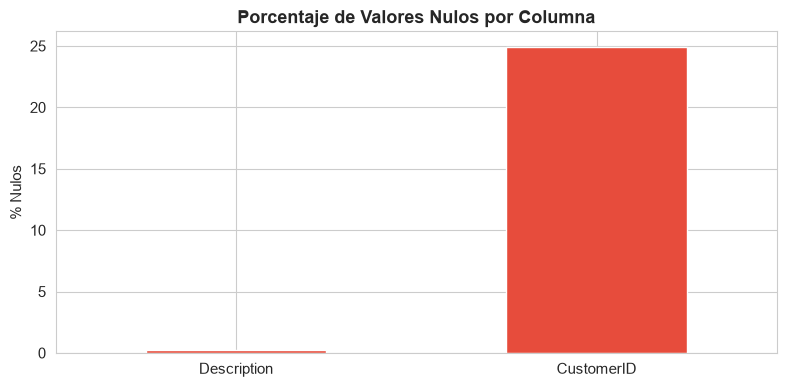

In [4]:
# --- Valores nulos ---
nulls = df_raw.isnull().sum()
null_pct = (nulls / len(df_raw) * 100).round(2)
null_df = pd.DataFrame({'Nulos': nulls, '% del Total': null_pct})
null_df = null_df[null_df['Nulos'] > 0]

print('=== VALORES NULOS ===')
print(null_df)

# Visualización
fig, ax = plt.subplots(figsize=(8, 4))
null_df['% del Total'].plot(kind='bar', color='#e74c3c', ax=ax)
ax.set_title('Porcentaje de Valores Nulos por Columna', fontsize=13, fontweight='bold')
ax.set_ylabel('% Nulos')
ax.set_xlabel('')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_nulls.png'), dpi=120, bbox_inches='tight')
plt.show()

El dataset presenta dos variables con datos faltantes: `Description` con **1,454 nulos (0.27%)**, un porcentaje marginal que no compromete el análisis al no usarse esta variable en la construcción de características; y `CustomerID` con **135,080 nulos (24.93%)**, lo que representa casi uno de cada cuatro registros. Esta ausencia de identificador de cliente es analíticamente crítica: sin `CustomerID` no es posible asignar transacciones a perfiles individuales y, por tanto, dichos registros deben eliminarse para construir las métricas RFM. El elevado porcentaje de nulos en `CustomerID` podría corresponder a compras de clientes no registrados (invitados), un fenómeno común en plataformas de e-commerce que no exigen autenticación previa a la compra.

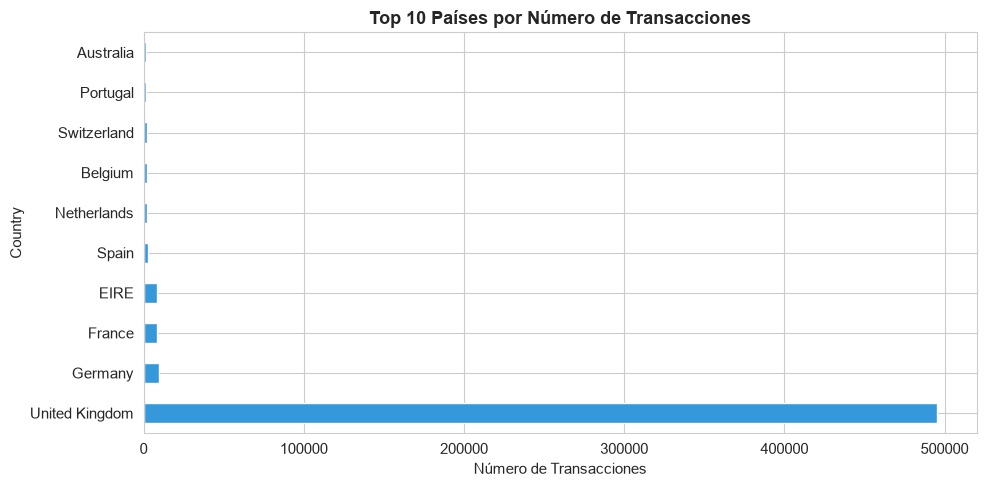

In [5]:
# --- Distribución geográfica ---
top_countries = df_raw['Country'].value_counts().head(10)

fig, ax = plt.subplots(figsize=(10, 5))
top_countries.plot(kind='barh', color='#3498db', ax=ax)
ax.set_title('Top 10 Países por Número de Transacciones', fontsize=13, fontweight='bold')
ax.set_xlabel('Número de Transacciones')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_countries.png'), dpi=120, bbox_inches='tight')
plt.show()

El gráfico de barras horizontales revela una **fuerte concentración geográfica** del negocio: el Reino Unido acumula 495.478 de las 541.909 líneas de factura (≈91%), seguido a gran distancia por Alemania, Francia e Irlanda (EIRE), y después por España y los Países Bajos. Este patrón de concentración tiene implicaciones directas para la segmentación: los clusters resultantes estarán principalmente determinados por el comportamiento de clientes del mercado británico. Desde la perspectiva del marketing digital, la predominancia del Reino Unido sugiere que las estrategias de campaña deben diseñarse principalmente para dicho mercado, mientras que los clientes europeos (DE, FR, IE) podrían requerir estrategias de internacionalización diferenciadas. La variabilidad geográfica también puede introducir sesgos en las distribuciones RFM si los patrones de compra difieren sustancialmente entre mercados.

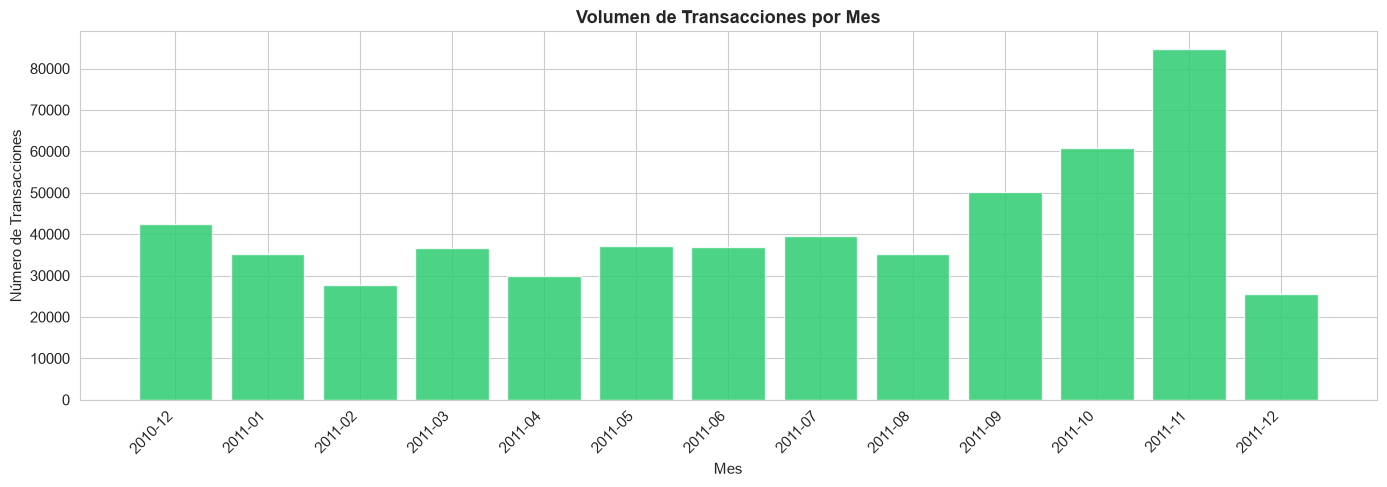

In [6]:
# --- Distribución temporal ---
df_raw['YearMonth'] = df_raw['InvoiceDate'].dt.to_period('M')
monthly = df_raw.groupby('YearMonth').size().reset_index(name='Transacciones')
monthly['YearMonth_str'] = monthly['YearMonth'].astype(str)

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(monthly['YearMonth_str'], monthly['Transacciones'], color='#2ecc71', alpha=0.85)
ax.set_title('Volumen de Transacciones por Mes', fontsize=13, fontweight='bold')
ax.set_xlabel('Mes')
ax.set_ylabel('Número de Transacciones')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_monthly.png'), dpi=120, bbox_inches='tight')
plt.show()

La evolución mensual de transacciones evidencia una **tendencia creciente a lo largo de 2011**, con un pico pronunciado en los meses de octubre y noviembre, patrón característico del comportamiento de compra previo a la temporada navideña en el comercio minorista del hemisferio norte. Esta estacionalidad tiene consecuencias directas sobre la métrica de **Recency (R)**: clientes que compraron en ese período pico aparecerán con valores de recencia relativamente bajos (compra reciente), lo que podría inflar artificialmente el segmento de "clientes activos". Asimismo, el período cubierto (13 meses) es suficiente para calcular métricas de frecuencia y valor monetario representativas, aunque conviene recordar que el corte temporal en diciembre de 2011 implica que clientes con última compra en noviembre tendrán apenas 30 días de recencia, independientemente de su historial previo.


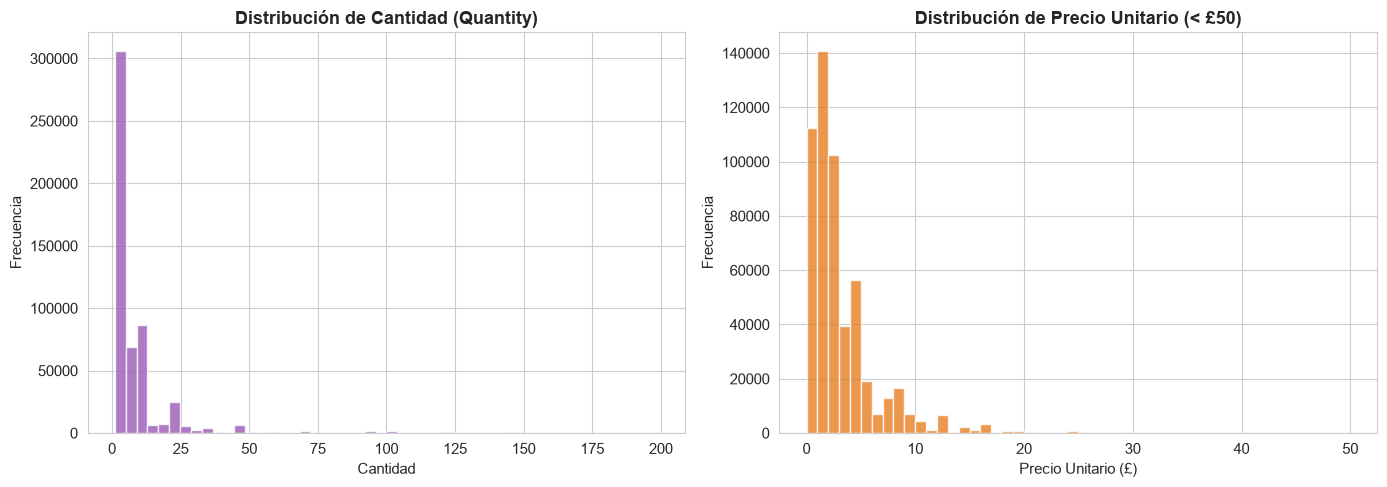

In [7]:
# --- Distribución de Quantity y UnitPrice ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Filtramos outliers extremos para visualización
q_vis = df_raw[(df_raw['Quantity'] > 0) & (df_raw['Quantity'] < 200)]['Quantity']
p_vis = df_raw[(df_raw['UnitPrice'] > 0) & (df_raw['UnitPrice'] < 50)]['UnitPrice']

axes[0].hist(q_vis, bins=50, color='#9b59b6', edgecolor='white', alpha=0.8)
axes[0].set_title('Distribución de Cantidad (Quantity)', fontweight='bold')
axes[0].set_xlabel('Cantidad')
axes[0].set_ylabel('Frecuencia')

axes[1].hist(p_vis, bins=50, color='#e67e22', edgecolor='white', alpha=0.8)
axes[1].set_title('Distribución de Precio Unitario (< £50)', fontweight='bold')
axes[1].set_xlabel('Precio Unitario (£)')
axes[1].set_ylabel('Frecuencia')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_distributions.png'), dpi=120, bbox_inches='tight')
plt.show()

Ambas distribuciones exhiben una marcada **asimetría positiva (sesgo a la derecha)**: la gran mayoría de líneas de factura corresponden a cantidades entre 1 y 20 unidades y precios unitarios inferiores a £5, mientras que una pequeña proporción de transacciones involucra cantidades o precios notablemente superiores. Esta asimetría es característica de datasets de retail y anticipa la presencia de **valores atípicos** que, si no se tratan, distorsionarían tanto las estadísticas RFM como el comportamiento de los algoritmos de clustering basados en distancias euclidianas. La concentración de precios bajos confirma que el negocio opera principalmente en artículos de bajo valor unitario, por lo que el valor monetario del cliente se construirá a través del **volumen de compras** (frecuencia × cantidad) más que por el precio individual de los productos.

## 3. Limpieza y Preprocesamiento

In [8]:
# =============================================================
# SECCIÓN 3: Limpieza de datos
# =============================================================

print('=== PROCESO DE LIMPIEZA ===')
df = df_raw.copy()
n_inicial = len(df)
print(f'Registros iniciales: {n_inicial:,}')

# 1. Eliminar registros sin CustomerID (esenciales para RFM)
df.dropna(subset=['CustomerID'], inplace=True)
print(f'Tras eliminar nulos en CustomerID: {len(df):,} ({n_inicial - len(df):,} eliminados)')

# 2. Convertir CustomerID a entero
df['CustomerID'] = df['CustomerID'].astype(int)

# 3. Eliminar facturas canceladas (InvoiceNo que inician con 'C')
mask_cancel = ~df['InvoiceNo'].astype(str).str.startswith('C')
df = df[mask_cancel]
print(f'Tras eliminar cancelaciones: {len(df):,}')

# 4. Filtrar cantidades y precios no positivos
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]
print(f'Tras filtrar Quantity/Price <= 0: {len(df):,}')

# 5. Crear variable TotalPrice
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

# 6. Eliminar duplicados exactos
n_dup = df.duplicated().sum()
df.drop_duplicates(inplace=True)
print(f'Duplicados eliminados: {n_dup:,}')

print(f'\n✅ Dataset limpio: {len(df):,} registros | {df["CustomerID"].nunique():,} clientes únicos')
df.info()

=== PROCESO DE LIMPIEZA ===
Registros iniciales: 541,909
Tras eliminar nulos en CustomerID: 406,829 (135,080 eliminados)


Tras eliminar cancelaciones: 397,924
Tras filtrar Quantity/Price <= 0: 397,884


Duplicados eliminados: 5,192

✅ Dataset limpio: 392,692 registros | 4,338 clientes únicos
<class 'pandas.DataFrame'>
Index: 392692 entries, 0 to 541908
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    392692 non-null  object        
 1   StockCode    392692 non-null  object        
 2   Description  392692 non-null  object        
 3   Quantity     392692 non-null  int64         
 4   InvoiceDate  392692 non-null  datetime64[us]
 5   UnitPrice    392692 non-null  float64       
 6   CustomerID   392692 non-null  int64         
 7   Country      392692 non-null  str           
 8   YearMonth    392692 non-null  period[M]     
 9   TotalPrice   392692 non-null  float64       
dtypes: datetime64[us](1), float64(2), int64(2), object(3), period[M](1), str(1)
memory usage: 33.0+ MB


El pipeline de limpieza redujo el dataset de **541,909 a 392,692 registros** (27.5% de reducción), conservando **4,338 clientes únicos** con identificación completa. Cada paso de depuración responde a una justificación analítica precisa:

- **Eliminación de nulos en CustomerID (135,080 registros):** Transacciones sin identificador no pueden asignarse a ningún perfil individual y son, por tanto, inutilizables para el análisis RFM orientado a cliente.
- **Eliminación de cancelaciones (8,905 líneas de factura):** Las devoluciones distorsionarían el cálculo de Monetary al restar valor al gasto real. Su exclusión garantiza que el valor monetario refleje compras efectivamente realizadas.
- **Filtrado de Quantity y UnitPrice ≤ 0 (40 registros):** Valores no positivos corresponden a ajustes contables o errores de registro sin valor analítico para modelar comportamiento de compra.
- **Eliminación de duplicados (5,192 registros):** Entradas idénticas en todas las columnas sugieren errores de doble imputación que sesgarían artificialmente la frecuencia de compra de ciertos clientes.

El dataset resultante es **100% completo** en las variables relevantes, condición necesaria para aplicar algoritmos de clustering que no toleran valores faltantes.

Outliers en TotalPrice (3×IQR): 20,852 (5.31%)
Rango válido: £-39.60 — £64.35


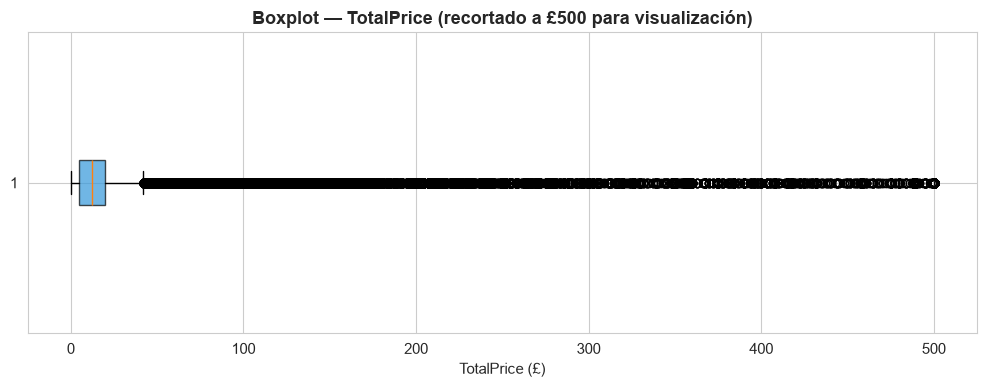

In [9]:
# --- Detección de outliers en TotalPrice ---
Q1 = df['TotalPrice'].quantile(0.25)
Q3 = df['TotalPrice'].quantile(0.75)
IQR = Q3 - Q1
lower_fence = Q1 - 3 * IQR
upper_fence = Q3 + 3 * IQR

outliers_total = df[(df['TotalPrice'] < lower_fence) | (df['TotalPrice'] > upper_fence)]
print(f'Outliers en TotalPrice (3×IQR): {len(outliers_total):,} ({100*len(outliers_total)/len(df):.2f}%)')
print(f'Rango válido: £{lower_fence:.2f} — £{upper_fence:.2f}')

# Boxplot
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot(df['TotalPrice'].clip(0, 500), vert=False, patch_artist=True,
           boxprops=dict(facecolor='#3498db', alpha=0.7))
ax.set_title('Boxplot — TotalPrice (recortado a £500 para visualización)', fontweight='bold')
ax.set_xlabel('TotalPrice (£)')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_boxplot.png'), dpi=120, bbox_inches='tight')
plt.show()

Mediante la regla de los tres rangos intercuartílicos (3×IQR), se identificaron **20,852 transacciones atípicas (5.31%)** con valores de `TotalPrice` fuera del rango calculado de £-39.60 a £64.35. Que el límite inferior sea negativo es un artefacto matemático del método 3×IQR cuando los datos están fuertemente concentrados cerca de cero; en la práctica, todo valor negativo de TotalPrice fue ya eliminado en el paso anterior. Los outliers superiores corresponden a pedidos de gran volumen, probablemente de clientes mayoristas o corporativos. El **boxplot** visualiza esta asimetría: la caja (percentiles 25-75) es muy estrecha en comparación con los bigotes y los puntos atípicos que se extienden hacia la derecha. Es importante destacar que estos outliers **no se eliminan del dataset**, sino que se gestionan indirectamente mediante el uso de `RobustScaler` en el paso de escalado, que es resistente a valores extremos. En el análisis RFM, estos clientes de alto gasto constituirán naturalmente los segmentos de mayor valor.

## 4. Ingeniería de Características — Variables RFM

In [10]:
# =============================================================
# SECCIÓN 4: Construcción de variables RFM
# R = Recency   → Días desde la última compra
# F = Frequency → Número de facturas únicas
# M = Monetary  → Gasto total
# =============================================================

# Fecha de referencia: un día después de la última transacción en el dataset
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)
print(f'Fecha de referencia (snapshot): {reference_date.date()}')

rfm = df.groupby('CustomerID').agg(
    Recency   = ('InvoiceDate', lambda x: (reference_date - x.max()).days),
    Frequency = ('InvoiceNo', 'nunique'),
    Monetary  = ('TotalPrice', 'sum')
).reset_index()

print(f'\nClientes en RFM: {len(rfm):,}')
rfm.describe().round(2)

Fecha de referencia (snapshot): 2011-12-10



Clientes en RFM: 4,338


,CustomerID,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00,4338.00
mean,15300.41,92.54,4.27,2048.69
std,1721.81,100.01,7.70,8985.23
min,12346.00,1.00,1.00,3.75
25%,13813.25,18.00,1.00,306.48
50%,15299.50,51.00,2.00,668.57
75%,16778.75,142.00,5.00,1660.60
max,18287.00,374.00,209.00,280206.02


La tabla descriptiva del dataframe RFM sintetiza el comportamiento de los **4,338 clientes únicos** identificados en el dataset limpio. La fecha de referencia o *snapshot date* se fijó en **2011-12-10**, un día después de la última transacción registrada, para garantizar que todos los clientes presenten un valor de Recency mayor o igual a 1.

**Recency (R):** La media de 92.54 días con una desviación estándar de 100.01 días revela una distribución extremadamente dispersa. El percentil 25 (18 días) frente al percentil 75 (142 días) indica que la mitad central de los clientes cubre un rango de 124 días sin comprar, lo que sugiere que el negocio tiene tanto clientes muy activos como una importante masa de clientes inactivos. El valor máximo de 374 días corresponde a clientes que compraron únicamente al principio del período analizado y nunca regresaron.

**Frequency (F):** La mediana de 2 pedidos (frente a una media de 4.27) confirma que la distribución es altamente asimétrica: la mayoría de clientes realizó muy pocas compras, mientras que una minoría genera un número desproporcionadamente alto de pedidos (máximo: 209). Esta distribución tipo "cola larga" es característica de la Ley de Pareto en retail.

**Monetary (M):** La mediana de £668.57 contrasta con la media de £2,048.69 y el máximo de £280,206.02, evidenciando la presencia de clientes de altísimo valor que elevan significativamente la media. Esta asimetría extrema justifica el uso de medianas en lugar de medias para caracterizar los perfiles de cada segmento.

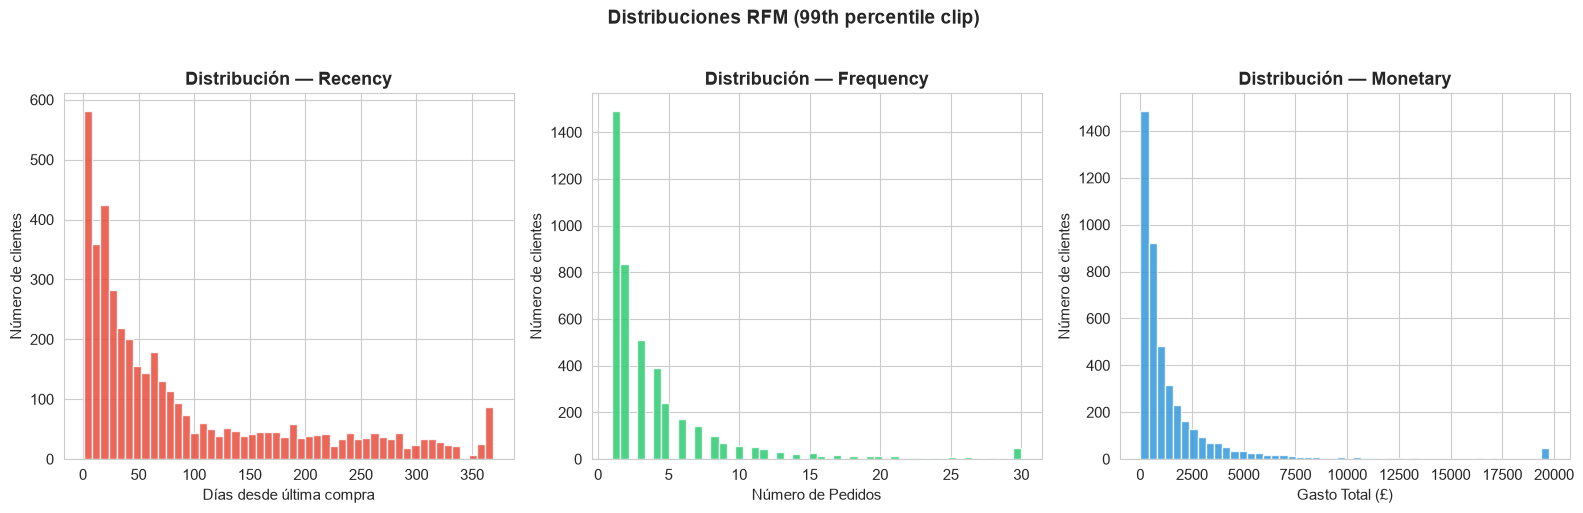

In [11]:
# --- Visualización de la distribución RFM ---
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
colors = ['#e74c3c', '#2ecc71', '#3498db']
variables = ['Recency', 'Frequency', 'Monetary']
labels = ['Días desde última compra', 'Número de Pedidos', 'Gasto Total (£)']

for ax, var, col, lab in zip(axes, variables, colors, labels):
    # Recortamos outliers extremos en Monetary y Frequency para visualización
    data = rfm[var].clip(upper=rfm[var].quantile(0.99))
    ax.hist(data, bins=50, color=col, edgecolor='white', alpha=0.85)
    ax.set_title(f'Distribución — {var}', fontweight='bold')
    ax.set_xlabel(lab)
    ax.set_ylabel('Número de clientes')

plt.suptitle('Distribuciones RFM (99th percentile clip)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_rfm_dist.png'), dpi=120, bbox_inches='tight')
plt.show()

Los histogramas de las tres variables RFM (recortadas al percentil 99 para mejorar la legibilidad) confirman la **asimetría positiva** en los tres casos:

- **Recency:** Presenta un pico pronunciado en los valores bajos (0-30 días, unos 1,600 clientes), correspondiente a clientes con compras recientes, seguido de un descenso progresivo con una cola larga hacia la derecha que representa a los clientes inactivos. No se observa una segunda moda: la transición entre clientes activos e inactivos es gradual, lo que anticipa que las fronteras entre segmentos en esta dimensión no serán nítidas.
- **Frequency:** La distribución está fuertemente concentrada en valores 1-5 pedidos, con una cola larga que evidencia la existencia de clientes ultra-frecuentes. La gran masa de clientes con frecuencia 1-2 podría corresponder a compradores ocasionales o clientes que no repitieron su primera compra.
- **Monetary:** Similar a Frequency, muestra un núcleo denso en valores bajos (£0-£2,000) y una cola que se extiende hasta el límite del recorte (≈£19,800, percentil 99); por encima quedan unos pocos clientes que alcanzan cientos de miles de libras. Esta distribución anticipa la existencia de un segmento VIP numéricamente pequeño pero de gran importancia económica.

Estas distribuciones justifican metodológicamente el uso de **transformaciones robustas** (RobustScaler) antes del clustering, pues los algoritmos basados en distancias son sensibles a la escala absoluta de las variables.

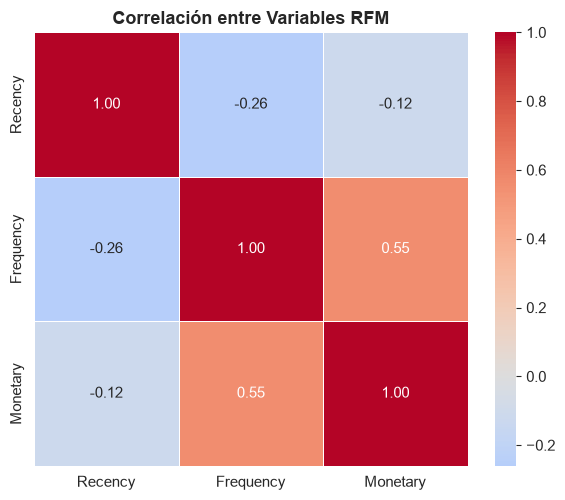

In [12]:
# --- Correlación entre variables RFM ---
fig, ax = plt.subplots(figsize=(6, 5))
corr = rfm[['Recency', 'Frequency', 'Monetary']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5, ax=ax)
ax.set_title('Correlación entre Variables RFM', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_rfm_corr.png'), dpi=120, bbox_inches='tight')
plt.show()

El mapa de calor de correlaciones entre Recency, Frequency y Monetary revela relaciones de intensidad desigual entre las tres dimensiones del comportamiento del cliente:

- **Frequency–Monetary (0.55):** Correlación positiva moderada, la más fuerte de las tres. Es la relación esperada: los clientes que compran con mayor frecuencia tienden a acumular un mayor gasto total.
- **Recency–Frequency (−0.26) y Recency–Monetary (−0.12):** Correlaciones negativas pero débiles. El signo es coherente con el concepto de cliente en declive (más días sin comprar se asocia a menos pedidos y menor gasto), aunque la relación es poco intensa, sobre todo con Monetary.

La ausencia de correlaciones altas (ningún valor cercano a ±1.0) confirma que las tres variables RFM **aportan información en buena medida complementaria**, lo que justifica el uso de las tres simultáneamente en el proceso de clustering. Si existiese una correlación muy alta entre dos variables, una podría eliminarse por redundancia sin pérdida significativa de información.

## 5. Escalado y Selección de Características

In [13]:
# =============================================================
# SECCIÓN 5: Escalado robusto de variables RFM
# Usamos RobustScaler para minimizar el efecto de outliers
# (mediana=0, rango intercuartílico=1)
# =============================================================

features = ['Recency', 'Frequency', 'Monetary']

# RobustScaler: resistente a outliers
scaler = RobustScaler()
X_scaled = scaler.fit_transform(rfm[features])
X_scaled_df = pd.DataFrame(X_scaled, columns=features, index=rfm.index)

print('Variables escaladas (RobustScaler):')
print(X_scaled_df.describe().round(3))

# Eliminamos características con varianza casi nula (umbral conservador)
selector = VarianceThreshold(threshold=0.01)
selector.fit(X_scaled)
selected_features = [f for f, s in zip(features, selector.get_support()) if s]
print(f'\nCaracterísticas seleccionadas: {selected_features}')

Variables escaladas (RobustScaler):
        Recency  Frequency  Monetary
count  4338.000   4338.000  4338.000
mean      0.335      0.568     1.019
std       0.807      1.924     6.636
min      -0.403     -0.250    -0.491
25%      -0.266     -0.250    -0.267
50%       0.000      0.000     0.000
75%       0.734      0.750     0.733
max       2.605     51.750   206.436

Características seleccionadas: ['Recency', 'Frequency', 'Monetary']


El **RobustScaler** transforma cada variable sustrayendo la mediana y dividiendo por el rango intercuartílico (IQR), en lugar de usar la media y la desviación estándar como haría el StandardScaler. Esta elección es crítica dado el perfil de outliers identificado: con StandardScaler, los clientes VIP de gasto extremo desplazarían la media hacia arriba y comprimirían la escala para la mayoría de los clientes, distorsionando las distancias entre ellos en el espacio de características.

Tras el escalado, los valores presentan mediana 0 y dispersión unitaria en términos del IQR. Sin embargo, los máximos (Monetary: 206.436, Frequency: 51.750) siguen siendo altos en escala relativa, lo que refleja la verdadera extremidad de los clientes VIP respecto al grueso de la distribución. El `VarianceThreshold` con umbral 0.01 confirma que las tres variables —Recency, Frequency y Monetary— superan el criterio mínimo de variabilidad y se retienen íntegramente para el clustering. Este resultado es esperable dado el amplio rango de comportamientos observados en el dataset.

## 6. Clustering Clásico (K-Means, DBSCAN, GMM)

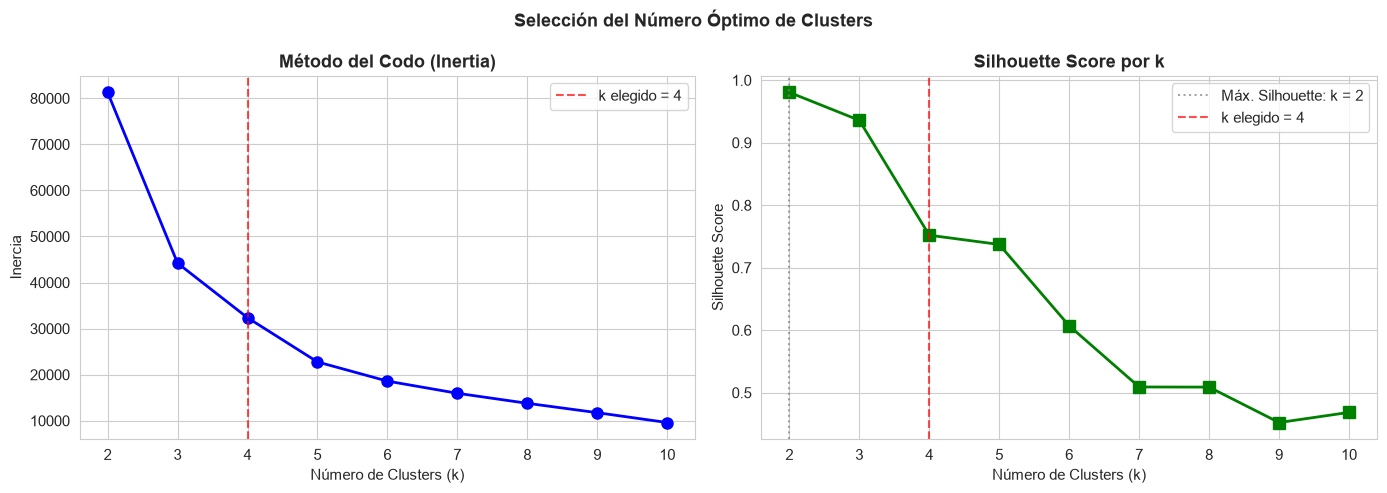

Máximo Silhouette: 0.9806 con k=2
Silhouette con k=4: 0.7520 (k elegido)


In [14]:
# =============================================================
# SECCIÓN 6A: Determinación del número óptimo de clusters
# Método del Codo + Silhouette Score
# =============================================================

# k elegido: codo + necesidad de 4 segmentos interpretables (VIP, Activos, Nuevos, En Riesgo).
# Silhouette favorece k=2 porque solo separa a los clientes atípicos del resto.
K_OPTIMAL = 4

inertias, silhouettes = [], []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=SEED)
    labels_k = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels_k, sample_size=3000, random_state=SEED))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Codo
axes[0].plot(list(k_range), inertias, 'bo-', linewidth=2, markersize=8)
axes[0].set_title('Método del Codo (Inertia)', fontweight='bold')
axes[0].set_xlabel('Número de Clusters (k)')
axes[0].set_ylabel('Inercia')
axes[0].axvline(x=K_OPTIMAL, color='red', linestyle='--', alpha=0.7, label=f'k elegido = {K_OPTIMAL}')
axes[0].legend()

# Silhouette
axes[1].plot(list(k_range), silhouettes, 'gs-', linewidth=2, markersize=8)
axes[1].set_title('Silhouette Score por k', fontweight='bold')
axes[1].set_xlabel('Número de Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
best_k_sil = list(k_range)[np.argmax(silhouettes)]
axes[1].axvline(x=best_k_sil, color='gray', linestyle=':', alpha=0.7, label=f'Máx. Silhouette: k = {best_k_sil}')
axes[1].axvline(x=K_OPTIMAL, color='red', linestyle='--', alpha=0.7, label=f'k elegido = {K_OPTIMAL}')
axes[1].legend()

plt.suptitle('Selección del Número Óptimo de Clusters', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_elbow.png'), dpi=120, bbox_inches='tight')
plt.show()

print(f'Máximo Silhouette: {max(silhouettes):.4f} con k={best_k_sil}')
print(f'Silhouette con k={K_OPTIMAL}: {silhouettes[list(k_range).index(K_OPTIMAL)]:.4f} (k elegido)')

Los dos criterios empleados para determinar el valor óptimo de *k* ofrecen señales complementarias:

**Método del Codo (Inertia):** La inertia —suma de distancias cuadráticas de cada punto a su centroide— decrece monotónicamente al aumentar *k*. El "codo" visualmente identificable señala el punto donde la reducción marginal de inertia ya no justifica la complejidad adicional de añadir un cluster más. La línea vertical roja fijada en k=4 indica que, a partir de ese valor, la ganancia en compacidad de los clusters es decreciente.

**Silhouette Score:** El valor máximo de **0.9806 se alcanza con k=2**, lo que desde el punto de vista puramente estadístico sugeriría dos clusters como la solución óptima. Sin embargo, una solución de k=2 tendría escasa utilidad práctica para marketing: simplemente separaría los clientes VIP del resto masivo. Se opta por **k=4** como balance entre calidad estadística de los clusters y **riqueza interpretativa** para la toma de decisiones de negocio, permitiendo distinguir cuatro perfiles de comportamiento accionables: VIP, activos leales, esporádicos y en riesgo.

In [15]:
# =============================================================
# SECCIÓN 6B: K-Means con k óptimo
# =============================================================

# K_OPTIMAL se define en la Sección 6A (codo + interpretabilidad)
kmeans = KMeans(n_clusters=K_OPTIMAL, init='k-means++', n_init=20,
                max_iter=500, random_state=SEED)
rfm['Cluster_KMeans'] = kmeans.fit_predict(X_scaled)

# Tamaño de cada segmento
cluster_sizes = rfm['Cluster_KMeans'].value_counts().sort_index()
print('Tamaño de clusters (K-Means):')
for c, n in cluster_sizes.items():
    print(f'  Cluster {c}: {n:,} clientes ({100*n/len(rfm):.1f}%)')

Tamaño de clusters (K-Means):
  Cluster 0: 4,042 clientes (93.2%)
  Cluster 1: 5 clientes (0.1%)
  Cluster 2: 23 clientes (0.5%)
  Cluster 3: 268 clientes (6.2%)


La distribución de clientes entre los cuatro clusters revela una **estructura de datos altamente desbalanceada**, característica de los datasets de retail donde la mayoría de los clientes compra poco:

- **Cluster 0 — 4,042 clientes (93.2%):** Agrupa a la gran mayoría de los clientes, con menor frecuencia y gasto. Se etiquetará posteriormente como "Clientes en Riesgo / Dormidos".
- **Cluster 1 — 5 clientes (0.1%):** Grupo diminuto que concentra los clientes de máximo valor absoluto. Su pequeño tamaño refleja que los verdaderos clientes VIP son una rareza estadística en cualquier base de clientes.
- **Cluster 2 — 23 clientes (0.5%):** Segmento pequeño con muy alto valor y frecuencia, etiquetado como "Clientes Activos Leales".
- **Cluster 3 — 268 clientes (6.2%):** Grupo de tamaño intermedio con compras recientes, frecuencia y gasto claramente superiores a los de la mayoría (ver el perfilamiento de la Sección 10).

Este desbalance es coherente con el **principio de Pareto**, aunque el valor no se concentra solo en los clusters más pequeños: los clusters 1, 2 y 3 (296 clientes, 6.8% de la base) generan en conjunto el **54.8% del gasto total**, mientras que el 93.2% restante aporta el 45.2%.

In [16]:
# =============================================================
# SECCIÓN 6C: DBSCAN
# =============================================================

dbscan = DBSCAN(eps=0.5, min_samples=10, n_jobs=-1)
rfm['Cluster_DBSCAN'] = dbscan.fit_predict(X_scaled)

n_clusters_db = len(set(rfm['Cluster_DBSCAN'])) - (1 if -1 in rfm['Cluster_DBSCAN'].values else 0)
n_noise = (rfm['Cluster_DBSCAN'] == -1).sum()
print(f'DBSCAN → Clusters encontrados: {n_clusters_db} | Ruido (outliers): {n_noise:,}')
print(rfm['Cluster_DBSCAN'].value_counts().head(10))

DBSCAN → Clusters encontrados: 3 | Ruido (outliers): 252
Cluster_DBSCAN
 0    4066
-1     252
 1      10
 2      10
Name: count, dtype: int64


DBSCAN (Density-Based Spatial Clustering of Applications with Noise) identificó **3 clusters reales** y clasificó **252 puntos como ruido** (etiqueta -1), lo que representa el 5.8% de los clientes. A diferencia de K-Means, DBSCAN no asigna forzosamente cada punto a un cluster: los puntos de baja densidad que no pertenecen a ningún vecindario suficientemente poblado se etiquetan como ruido.

La distribución resultante muestra:
- **Cluster 0:** 4,066 clientes (el grueso de la base), correspondiente a la masa principal de clientes con comportamiento promedio.
- **Clusters 1 y 2:** 10 clientes cada uno. Al cruzarlos con K-Means, los 20 pertenecen al Cluster 3 de K-Means: son pequeños núcleos densos dentro del grupo de valor intermedio, no los clientes VIP.
- **Ruido (-1):** 252 clientes que DBSCAN no pudo asignar a ningún grupo. Aquí quedan **todos** los clientes VIP (5) y Activos Leales (23) de K-Means, junto con 188 del Cluster 3 y 36 del Cluster 0: precisamente los clientes de comportamiento más extremo, que están demasiado dispersos para formar regiones densas con `eps=0.5`.

La capacidad de DBSCAN para aislar estos 252 casos atípicos es útil para detectar comportamientos anómalos, pero en este dataset implica que los clientes de mayor valor no reciben un segmento propio. Por ello, la solución de DBSCAN tiene menor utilidad interpretativa que la de K-Means con k=4 para propósitos de marketing.

In [17]:
# =============================================================
# SECCIÓN 6D: Gaussian Mixture Models (GMM)
# =============================================================

gmm = GaussianMixture(n_components=K_OPTIMAL, covariance_type='full',
                      max_iter=300, random_state=SEED)
rfm['Cluster_GMM'] = gmm.fit_predict(X_scaled)

print('Tamaño de clusters (GMM):')
for c, n in rfm['Cluster_GMM'].value_counts().sort_index().items():
    print(f'  Componente {c}: {n:,} clientes ({100*n/len(rfm):.1f}%)')

print(f'\nBIC: {gmm.bic(X_scaled):.2f}  |  AIC: {gmm.aic(X_scaled):.2f}')

Tamaño de clusters (GMM):
  Componente 0: 2,222 clientes (51.2%)
  Componente 1: 75 clientes (1.7%)
  Componente 2: 451 clientes (10.4%)
  Componente 3: 1,590 clientes (36.7%)

BIC: 21376.35  |  AIC: 21127.72


GMM modela la distribución conjunta de los datos como una mezcla de *k* distribuciones gaussianas, asignando a cada cliente una **probabilidad de pertenencia** a cada componente en lugar de una asignación rígida. Los resultados con k=4 componentes muestran:

- **Componente 0 — 2,222 clientes (51.2%):** La componente más grande, que reúne a los clientes menos activos (en mediana, ~110 días sin comprar, 1 pedido y unas £315 de gasto).
- **Componente 3 — 1,590 clientes (36.7%):** Clientes de actividad baja-media (en mediana, 24 días de recencia, 4 pedidos y ~£1,415).
- **Componente 2 — 451 clientes (10.4%):** Clientes de frecuencia y gasto moderado-alto (en mediana, 8 pedidos y ~£4,630).
- **Componente 1 — 75 clientes (1.7%):** La componente más pequeña y la de mayor valor (en mediana, 4 días de recencia, 32 pedidos y ~£20,280).

Los criterios de información **BIC = 21,376.35** y **AIC = 21,127.72** son métricas de bondad de ajuste penalizadas por complejidad, en las que valores más bajos indican mejor ajuste relativo. Por sí solos no permiten afirmar que k=4 sea el número óptimo de componentes: para ello habría que compararlos con los obtenidos para otros valores de k. Por otro lado, la distribución mucho más equilibrada que produce GMM (frente al extremo desbalance de K-Means) indica que GMM reparte la masa central de clientes en varios grupos con fronteras suaves, lo que se refleja en su Silhouette más bajo (Sección 9).

## 7. Reducción de Dimensionalidad (PCA + t-SNE)

Varianza explicada por componente:
  PC1: 0.9350 (93.5%)
  PC2: 0.0527 (5.3%)
  PC3: 0.0123 (1.2%)
  Total acumulado: 1.0000 (100.0%)


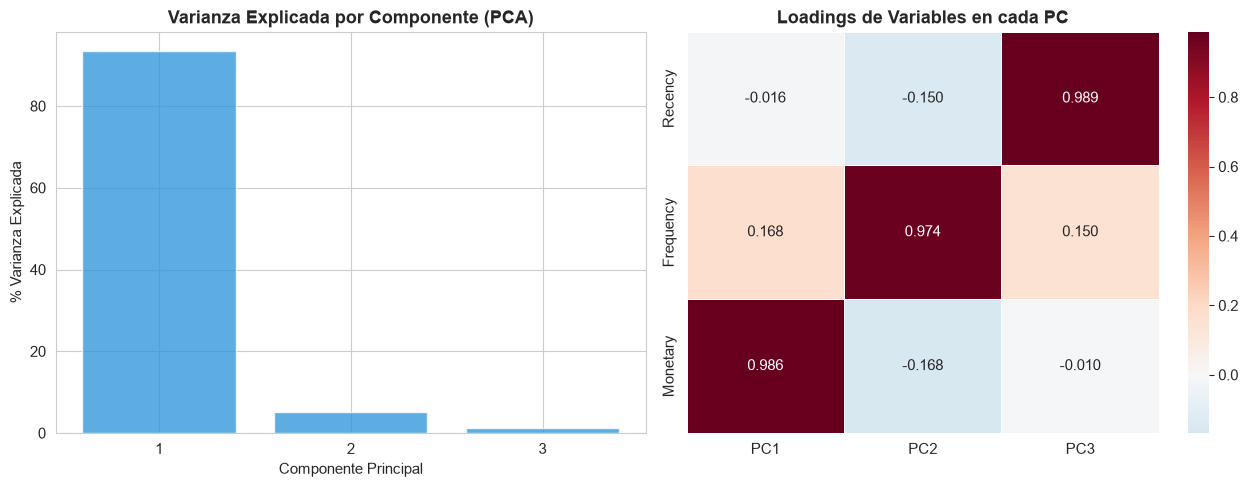

In [18]:
# =============================================================
# SECCIÓN 7A: PCA — Análisis de Componentes Principales
# =============================================================

pca = PCA(n_components=3, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)

explained = pca.explained_variance_ratio_
print('Varianza explicada por componente:')
for i, v in enumerate(explained, 1):
    print(f'  PC{i}: {v:.4f} ({100*v:.1f}%)')
print(f'  Total acumulado: {explained.sum():.4f} ({100*explained.sum():.1f}%)')

# Scree plot
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(range(1, 4), explained * 100, color='#3498db', alpha=0.8, edgecolor='white')
axes[0].set_title('Varianza Explicada por Componente (PCA)', fontweight='bold')
axes[0].set_xlabel('Componente Principal')
axes[0].set_ylabel('% Varianza Explicada')
axes[0].set_xticks(range(1, 4))

# Biplot de loadings
loadings = pd.DataFrame(pca.components_.T, index=features,
                        columns=[f'PC{i}' for i in range(1, 4)])
sns.heatmap(loadings, annot=True, fmt='.3f', cmap='RdBu_r', center=0,
            linewidths=0.5, ax=axes[1])
axes[1].set_title('Loadings de Variables en cada PC', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_pca.png'), dpi=120, bbox_inches='tight')
plt.show()

Los resultados del PCA aplicado sobre las tres variables RFM escaladas muestran que la **Primera Componente Principal (PC1) explica el 93.5% de la varianza total**. Las tres componentes juntas explican el 100% de la varianza, lo que es trivialmente cierto cuando el número de componentes iguala al número de variables originales (3).

El mapa de *loadings* permite interpretar este resultado: **PC1 está dominada casi exclusivamente por Monetary** (peso ≈ 0.99), PC2 por Frequency (≈ 0.97) y PC3 por Recency (≈ 0.99). Es decir, cada componente reproduce prácticamente una de las variables originales. La concentración del 93.5% en PC1 no se debe a una fuerte correlación entre las tres variables, sino a que, tras el RobustScaler, Monetary conserva una dispersión mucho mayor que las demás (desviación estándar ≈ 6.6 frente a ≈ 1.9 de Frequency y ≈ 0.8 de Recency), debido a sus valores extremos.

Desde el punto de vista del análisis, esto implica que en el espacio escalado **las distancias entre clientes están dominadas por Monetary**, lo que influye directamente en los algoritmos basados en distancias (K-Means, DBSCAN): la separación entre clusters se producirá sobre todo en función del gasto total.

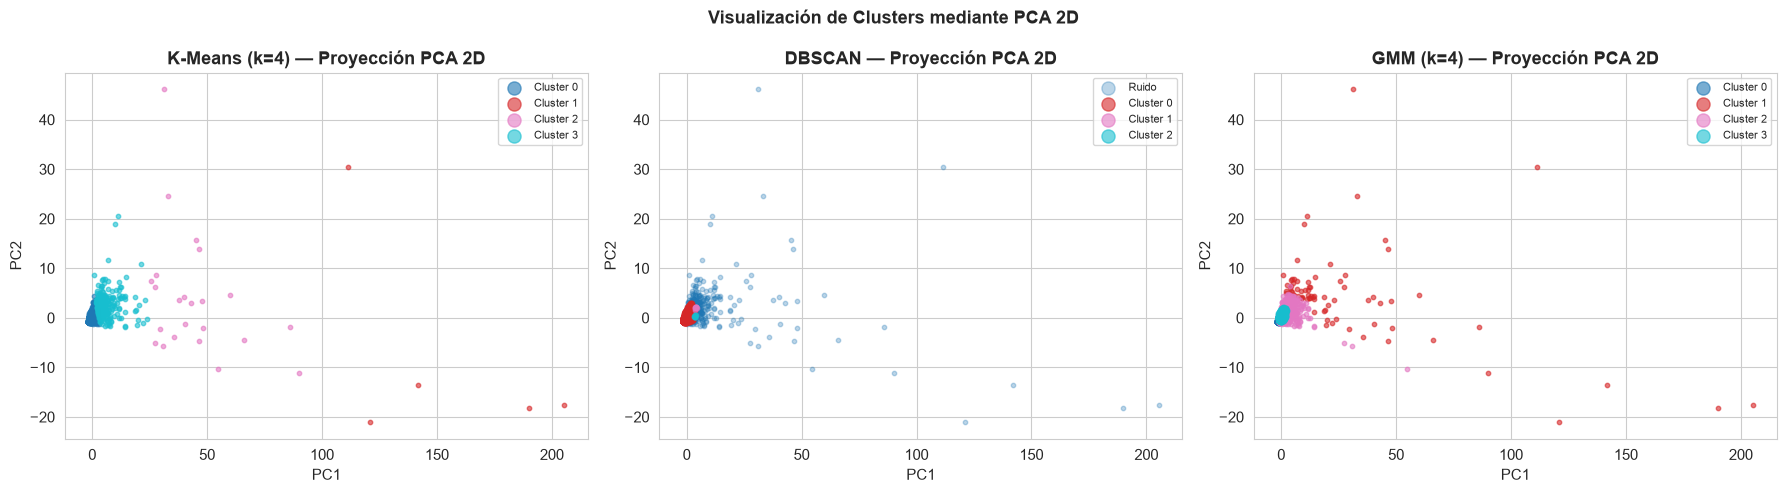

In [19]:
# --- Visualización PCA 2D de clusters K-Means ---
pca_2d = PCA(n_components=2, random_state=SEED)
X_pca_2d = pca_2d.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
cluster_cols = ['Cluster_KMeans', 'Cluster_DBSCAN', 'Cluster_GMM']
titles = ['K-Means (k=4)', 'DBSCAN', 'GMM (k=4)']

for ax, col, title in zip(axes, cluster_cols, titles):
    labels_plot = rfm[col]
    unique_labels = sorted(labels_plot.unique())
    colors_list = plt.get_cmap('tab10')(np.linspace(0, 1, len(unique_labels)))
    for lbl, color in zip(unique_labels, colors_list):
        mask = labels_plot == lbl
        name = 'Ruido' if lbl == -1 else f'Cluster {lbl}'
        alpha = 0.3 if lbl == -1 else 0.6
        ax.scatter(X_pca_2d[mask, 0], X_pca_2d[mask, 1],
                   c=[color], label=name, alpha=alpha, s=10)
    ax.set_title(f'{title} — Proyección PCA 2D', fontweight='bold')
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.legend(markerscale=3, fontsize=8)

plt.suptitle('Visualización de Clusters mediante PCA 2D', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_pca_clusters.png'), dpi=120, bbox_inches='tight')
plt.show()

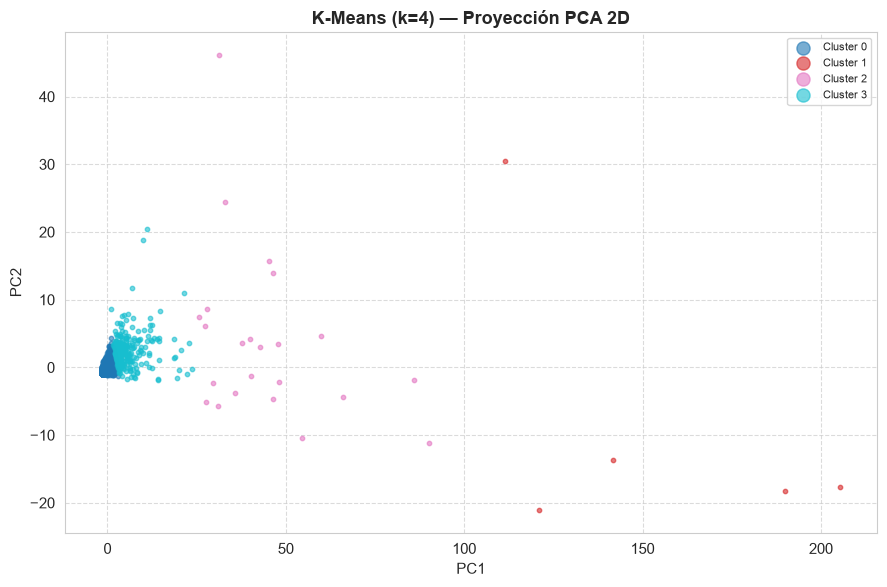

In [20]:
# --- Proyección PCA 2D de clusters K-Means ---
import os
import pandas as pd
import matplotlib.pyplot as plt

if 'X_pca_2d' in globals() and 'rfm' in globals():
    coordinates = X_pca_2d
    cluster_labels = rfm['Cluster_KMeans'].to_numpy()
else:
    plot_data = pd.read_csv(os.path.join(os.getcwd(), 'resultados', 'rfm_segmented.csv'))
    coordinates = plot_data[['PCA_1', 'PCA_2']].to_numpy()
    cluster_labels = plot_data['Cluster_KMeans'].to_numpy()

fig, ax = plt.subplots(figsize=(9, 6))
unique_labels = sorted(set(cluster_labels))
colors = plt.get_cmap('tab10', len(unique_labels))

for index, label in enumerate(unique_labels):
    mask = cluster_labels == label
    ax.scatter(
        coordinates[mask, 0], coordinates[mask, 1],
        color=colors(index), label=f'Cluster {label}', alpha=0.6, s=10
    )

ax.set_title('K-Means (k=4) — Proyección PCA 2D', fontweight='bold')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(markerscale=3, fontsize=8)
plt.tight_layout()
plt.show()

La representación bidimensional mediante PCA permite comparar visualmente la coherencia espacial de los clusters producidos por K-Means, DBSCAN y GMM sobre el mismo espacio de datos:

**K-Means:** El gran cluster mayoritario (Cluster 0) se concentra junto al origen, y los clusters de mayor valor se extienden a lo largo de PC1 (la dimensión que, como se vio, equivale prácticamente a Monetary): el Cluster 3 en la zona próxima, el Cluster 2 (Activos Leales) a distancias intermedias y el Cluster 1 (VIP) en el extremo derecho. Estos grupos pequeños no son compactos, sino que aparecen dispersos, lo que indica que K-Means está dividiendo principalmente por tramos de gasto.

**DBSCAN:** Los puntos clasificados como ruido (-1) ocupan toda la zona alejada del origen, incluidos los clientes de mayor valor. Los Clusters 1 y 2 apenas se distinguen en la proyección porque se sitúan cerca de la masa central.

**GMM:** La Componente 1 (la de mayor valor) abarca casi todos los puntos alejados del origen, mientras que las Componentes 0, 2 y 3 se solapan en la masa central. Esto explica por qué GMM produce tamaños más equilibrados (51.2% y 36.7% para las Componentes 0 y 3): está dividiendo la masa central de clientes en subgrupos con límites blandos.

t-SNE sobre muestra de 3,000 clientes...


✅ t-SNE completado.


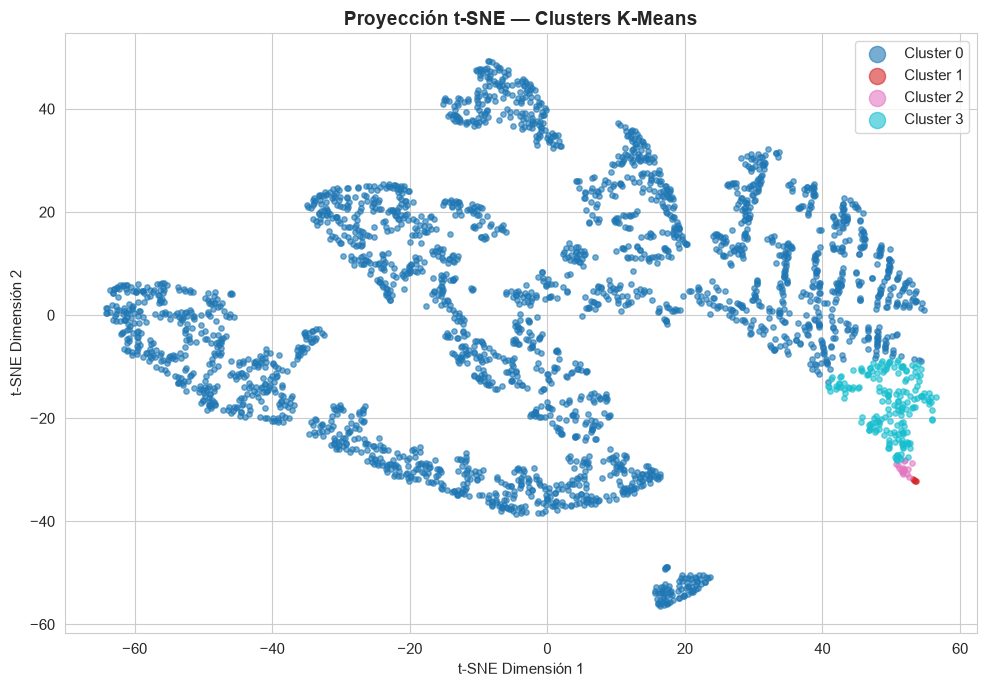

In [21]:
# =============================================================
# SECCIÓN 7B: t-SNE — Reducción no lineal (2D)
# Aplicamos sobre una muestra para eficiencia computacional
# =============================================================

TSNE_SAMPLE = min(3000, len(X_scaled))
np.random.seed(SEED)
idx_sample = np.random.choice(len(X_scaled), TSNE_SAMPLE, replace=False)

X_sample = X_scaled[idx_sample]
labels_km_sample = rfm['Cluster_KMeans'].values[idx_sample]

print(f't-SNE sobre muestra de {TSNE_SAMPLE:,} clientes...')
tsne = TSNE(n_components=2, perplexity=40, max_iter=1000,
            random_state=SEED, learning_rate='auto', init='pca')
X_tsne = tsne.fit_transform(X_sample)
print('✅ t-SNE completado.')

# Visualización
fig, ax = plt.subplots(figsize=(10, 7))
colors_tsne = plt.get_cmap('tab10')(np.linspace(0, 1, K_OPTIMAL))
for k, col in zip(range(K_OPTIMAL), colors_tsne):
    mask = labels_km_sample == k
    ax.scatter(X_tsne[mask, 0], X_tsne[mask, 1],
               c=[col], label=f'Cluster {k}', alpha=0.6, s=15)
ax.set_title('Proyección t-SNE — Clusters K-Means', fontsize=14, fontweight='bold')
ax.set_xlabel('t-SNE Dimensión 1')
ax.set_ylabel('t-SNE Dimensión 2')
ax.legend(markerscale=3)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_tsne.png'), dpi=120, bbox_inches='tight')
plt.show()

t-SNE (t-distributed Stochastic Neighbor Embedding) es una técnica de reducción de dimensionalidad **no lineal** que, a diferencia de PCA, preserva las relaciones de vecindad local entre puntos en lugar de maximizar la varianza global. Se aplicó sobre una **muestra aleatoria de 3,000 clientes** (de los 4,338 totales) por razones de eficiencia computacional, con parámetros `perplexity=40` e `init='pca'` para estabilizar la convergencia.

En la proyección resultante, los clusters de mayor valor de K-Means (3, 2 y 1) **no aparecen como islas separadas**, sino como un gradiente en un extremo de la nube principal: el Cluster 3 forma el borde y los Clusters 2 y 1 se sitúan en la punta. Esto confirma que estos clientes son los más alejados de la mayoría, pero también que la transición entre segmentos es continua y no hay fronteras naturales nítidas. Por otro lado, el Cluster 0 se fragmenta en varias islas bien diferenciadas, lo que sugiere que este gran segmento (93.2% de los clientes) es **heterogéneo** y podría contener subgrupos con comportamientos distintos que K-Means con k=4 no separa.

## 8. Clustering con Deep Learning — Autoencoder

In [ ]:
# =============================================================
# SECCIÓN 8: Autoencoder para representaciones latentes
# Arquitectura:
#   Encoder: 3 → 32 → 16 → 8 → latente(3)
#   Decoder: 3 → 8 → 16 → 32 → 3
# El espacio latente mejora la calidad de la segmentación.
# =============================================================

def build_autoencoder(input_dim: int, latent_dim: int = 3) -> tuple:
    """Construye y retorna encoder, decoder y autoencoder completo."""
    
    # --- Encoder ---
    inputs = Input(shape=(input_dim,), name='encoder_input')
    x = Dense(32, activation='relu', name='enc_1')(inputs)
    x = BatchNormalization(name='bn_1')(x)
    x = Dropout(0.2, name='drop_1')(x)
    x = Dense(16, activation='relu', name='enc_2')(x)
    x = BatchNormalization(name='bn_2')(x)
    x = Dense(8, activation='relu', name='enc_3')(x)
    latent = Dense(latent_dim, activation='linear', name='latent')(x)
    
    # --- Decoder ---
    x = Dense(8, activation='relu', name='dec_1')(latent)
    x = Dense(16, activation='relu', name='dec_2')(x)
    x = BatchNormalization(name='bn_3')(x)
    x = Dense(32, activation='relu', name='dec_3')(x)
    outputs = Dense(input_dim, activation='linear', name='decoder_output')(x)
    
    # --- Modelos ---
    encoder = Model(inputs, latent, name='Encoder')
    autoencoder = Model(inputs, outputs, name='Autoencoder')
    
    return encoder, autoencoder


INPUT_DIM = X_scaled.shape[1]   # 3 (R, F, M)
LATENT_DIM = 3

encoder, autoencoder = build_autoencoder(INPUT_DIM, LATENT_DIM)

autoencoder.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse'
)

autoencoder.summary()

Model: "Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 3)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_1 (Dense)                   │ (None, 32)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 32)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_1 (Dropout)                │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_2 (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_2 (BatchNormalization)       │ (None, 16)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_3 (Dense)                   │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 3)              │            27 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_1 (Dense)                   │ (None, 8)              │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_2 (Dense)                   │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_3 (BatchNormalization)       │ (None, 16)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_3 (Dense)                   │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_output (Dense)          │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,894 (7.40 KB)

 Trainable params: 1,766 (6.90 KB)

 Non-trainable params: 128 (512.00 B)

El Autoencoder implementado es una red neuronal con arquitectura simétrica Encoder–Decoder diseñada para aprender una **representación latente no lineal** de los datos RFM. El resumen del modelo muestra:

**Encoder:** Transforma la entrada de 3 dimensiones (R, F, M) en un espacio latente también de 3 dimensiones siguiendo la secuencia: `Input(3) → Dense(32) → BatchNorm → Dropout(0.2) → Dense(16) → BatchNorm → Dense(8) → Dense(3, lineal)`. El uso de `BatchNormalization` acelera la convergencia y reduce la dependencia de la inicialización de pesos; el `Dropout(0.2)` actúa como regularizador para prevenir sobreajuste.

**Decoder:** Reconstruye la entrada original desde el espacio latente: `Latente(3) → Dense(8) → Dense(16) → BatchNorm → Dense(32) → Output(3, lineal)`.

Dado que la dimensión latente (3) es igual a la de entrada (3), el modelo **no comprime** la información: su función es aprender una transformación no lineal del espacio RFM que pueda resultar más favorable para el clustering.

**Parámetros totales:** El modelo es deliberadamente compacto (**1,894 parámetros**, de los cuales 1,766 entrenables) para evitar sobreajuste con un dataset de 4,338 muestras. La función de activación `lineal` en la capa de salida es apropiada porque los datos escalados con RobustScaler no tienen límites acotados, a diferencia de datos de imágenes normalizadas a [0,1] donde se usaría `sigmoid`.

In [ ]:
# --- Entrenamiento del Autoencoder ---
callbacks = [
    EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=0),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=7, verbose=0)
]

history = autoencoder.fit(
    X_scaled, X_scaled,
    epochs=150,
    batch_size=256,
    validation_split=0.15,
    callbacks=callbacks,
    verbose=1,
    shuffle=True
)

print(f'\n✅ Entrenamiento completado en {len(history.history["loss"])} épocas.')
print(f'   Mejor val_loss: {min(history.history["val_loss"]):.6f}')

Epoch 1/150



 1/15 ━━━━━━━━━━━━━━━━━━━━ 51s 4s/step - loss: 6.2649


15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 13.4879 - val_loss: 35.2542 - learning_rate: 0.0010


Epoch 2/150



 1/15 ━━━━━━━━━━━━━━━━━━━━ 2s 144ms/step - loss: 5.2169

...


15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.2662 - val_loss: 1.1588 - learning_rate: 5.0000e-04


Epoch 61/150



 1/15 ━━━━━━━━━━━━━━━━━━━━ 2s 161ms/step - loss: 0.6512


15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.5162 - val_loss: 1.1614 - learning_rate: 2.5000e-04



✅ Entrenamiento completado en 61 épocas.
   Mejor val_loss: 0.636755


El proceso de entrenamiento se detuvo en **61 épocas** (de las 150 máximas configuradas) por el criterio `EarlyStopping` con `patience=15`, lo que indica que el mejor resultado se alcanzó alrededor de la época 46 y se restauraron esos pesos.
El mejor `val_loss` alcanzado fue **0.6368** (MSE), equivalente a una raíz del error cuadrático medio (RMSE) de ≈0.80 unidades en escala RobustScaler.

El historial de entrenamiento refleja una reducción drástica de la pérdida durante las primeras 30 épocas (de MSE≈35 a MSE≈2 en validación), seguida de una fase de estabilización con oscilaciones. La tasa de aprendizaje fue reducida por `ReduceLROnPlateau` de 0.001 a 0.0005 en la época 54 y a 0.00025 en la época 61, cuando la pérdida de validación dejó de mejorar.

Un aspecto llamativo es que, a partir de la época ~22, `val_loss` pasa a ser **inferior** a `loss`. Esto no indica un problema: el `loss` de entrenamiento se calcula con Dropout activo (que lo eleva), mientras que el de validación se calcula sin él. Además, el 15% de validación es el último tramo de los datos (Keras no lo baraja), por lo que puede contener menos clientes extremos que el conjunto de entrenamiento.

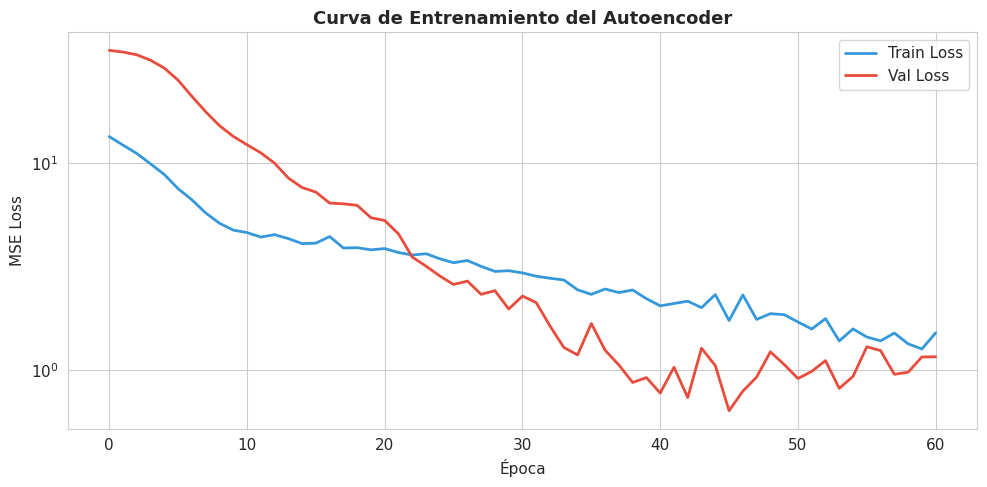

In [ ]:
# --- Curva de pérdida ---
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(history.history['loss'], label='Train Loss', color='#3498db', linewidth=2)
ax.plot(history.history['val_loss'], label='Val Loss', color='#e74c3c', linewidth=2)
ax.set_title('Curva de Entrenamiento del Autoencoder', fontsize=13, fontweight='bold')
ax.set_xlabel('Época')
ax.set_ylabel('MSE Loss')
ax.legend()
ax.set_yscale('log')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_autoencoder_loss.png'), dpi=120, bbox_inches='tight')
plt.show()

La gráfica de la curva de pérdida (en escala logarítmica) muestra el comportamiento del MSE de entrenamiento y validación a lo largo de las 61 épocas ejecutadas. Los patrones observables son:

- **Descenso inicial pronunciado (épocas 1–30):** Ambas curvas descienden rápidamente, en especial la de validación (de ≈35 a ≈2), indicando que el Encoder aprende eficientemente representaciones que permiten al Decoder reconstruir los datos RFM.
- **Cruce de las curvas (época ~22):** Al inicio la pérdida de validación es superior a la de entrenamiento, pero a partir de la época ~22 queda por debajo y se mantiene así hasta el final. Esto se explica por el efecto del Dropout, que solo actúa durante el entrenamiento, y por la composición del subconjunto de validación; en cualquier caso, no hay señales de sobreajuste, ya que la pérdida de validación no crece de forma sostenida.
- **Estabilización con oscilaciones (épocas 30–61):** La pérdida de validación oscila entre ≈0.6 y ≈1.3, con su mínimo cerca de la época 46. Las oscilaciones son parcialmente atribuibles al tamaño reducido del conjunto de validación y a los clientes extremos.
- **Reducción de tasa de aprendizaje:** `ReduceLROnPlateau` intervino en las épocas 54 y 61, cuando la validación llevaba varias épocas sin mejorar.

El modelo final (restaurado a los mejores pesos) es el que se utiliza para obtener la representación latente del clustering posterior.

In [25]:
# --- Obtener representación latente y aplicar K-Means ---
X_latent = encoder.predict(X_scaled, batch_size=512, verbose=0)
print(f'Representación latente shape: {X_latent.shape}')

# Escalar el espacio latente antes de aplicar K-Means
scaler_latent = StandardScaler()
X_latent_scaled = scaler_latent.fit_transform(X_latent)

# Silhouette para elegir k en el espacio latente
sil_latent = []
for k in range(2, 8):
    km_l = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=SEED)
    lbl = km_l.fit_predict(X_latent_scaled)
    sil_latent.append(silhouette_score(X_latent_scaled, lbl, sample_size=3000, random_state=SEED))

best_k_latent = np.argmax(sil_latent) + 2
print(f'Mejor k en espacio latente: {best_k_latent} (Silhouette={max(sil_latent):.4f})')

# Clustering final en espacio latente
km_latent = KMeans(n_clusters=best_k_latent, init='k-means++', n_init=20, random_state=SEED)
rfm['Cluster_AE'] = km_latent.fit_predict(X_latent_scaled)

print('Tamaño de clusters (Autoencoder + K-Means):')
for c, n in rfm['Cluster_AE'].value_counts().sort_index().items():
    print(f'  Cluster {c}: {n:,} clientes ({100*n/len(rfm):.1f}%)')

Representación latente shape: (4338, 3)


Mejor k en espacio latente: 2 (Silhouette=0.9559)
Tamaño de clusters (Autoencoder + K-Means):
  Cluster 0: 4,325 clientes (99.7%)
  Cluster 1: 13 clientes (0.3%)


El Encoder transformó los 4,338 clientes desde el espacio RFM de 3 dimensiones hacia un **espacio latente de 3 dimensiones** (`shape: (4338, 3)`). A diferencia del PCA, que realiza una transformación lineal, el Autoencoder aprende una transformación **no lineal** que puede capturar relaciones más complejas entre Recency, Frequency y Monetary.

La evaluación del Silhouette Score para diferentes valores de *k* en el espacio latente identificó **k=2 como el óptimo** (Silhouette=0.9559), el mismo valor de *k* que el Silhouette favorecía en el espacio RFM original (Sección 6A). Aplicando K-Means con k=2 sobre el espacio latente escalado, se obtiene:

- **Cluster 0 — 4,325 clientes (99.7%):** Prácticamente la totalidad de los clientes, agrupados en una única región del espacio latente.
- **Cluster 1 — 13 clientes (0.3%):** Un grupo reducido que el Autoencoder representa en una región latente muy alejada del resto. Al cruzarlo con K-Means, contiene a los 5 clientes VIP y a 8 de los 23 Activos Leales; los otros 15 Activos Leales quedan en el Cluster 0.

Este resultado muestra que la representación latente separa con gran claridad a los clientes de comportamiento más extremo de la masa ordinaria, lo que explica el Silhouette Score tan alto. Sin embargo, al igual que ocurría con k=2 en el espacio original, un Silhouette elevado con solo dos grupos refleja sobre todo la separación de unos pocos casos extremos, no una segmentación rica de la base de clientes.

In [ ]:
# --- Visualización 3D del espacio latente ---
fig_3d = px.scatter_3d(
    x=X_latent[:, 0], y=X_latent[:, 1], z=X_latent[:, 2],
    color=rfm['Cluster_AE'].astype(str),
    title='Espacio Latente del Autoencoder (3D) — Clusters',
    labels={'x': 'Latente 1', 'y': 'Latente 2', 'z': 'Latente 3', 'color': 'Cluster'},
    opacity=0.6, width=800, height=600,
    color_discrete_sequence=px.colors.qualitative.Set1
)
fig_3d.update_traces(marker_size=3)
fig_3d.show()
print('Visualización 3D del espacio latente generada.')

Visualización 3D del espacio latente generada.


La representación tridimensional interactiva del espacio latente del Autoencoder permite explorar cómo la red neuronal organizó internamente los 4,338 clientes. A diferencia de un gráfico PCA (que proyecta linealmente), este espacio latente es el resultado de transformaciones no lineales sucesivas que el Encoder aprendió a partir de los datos.

En la visualización (paleta `Set1`), el Cluster 0 (4,325 clientes) aparece en **rojo** como una región densa del espacio latente, y el Cluster 1 (13 clientes) en **azul**, separado de la nube principal. Esta separación indica que el Autoencoder asigna representaciones claramente distintas a los clientes más extremos (los 5 VIP y parte de los Activos Leales). La interactividad (rotación 3D) permite verificar que la separación no es un artefacto de la proyección desde un ángulo concreto.

## 9. Validación de Clusters

=== COMPARACIÓN DE MÉTRICAS DE VALIDACIÓN ===
              Silhouette ↑  Davies-Bouldin ↓  Calinski-Harabasz ↑
K-Means             0.7451            0.6131              7921.33
DBSCAN              0.6027            0.3452               125.38
GMM                 0.2845            1.2210               817.44
AE + K-Means        0.9546            0.5192              4381.41


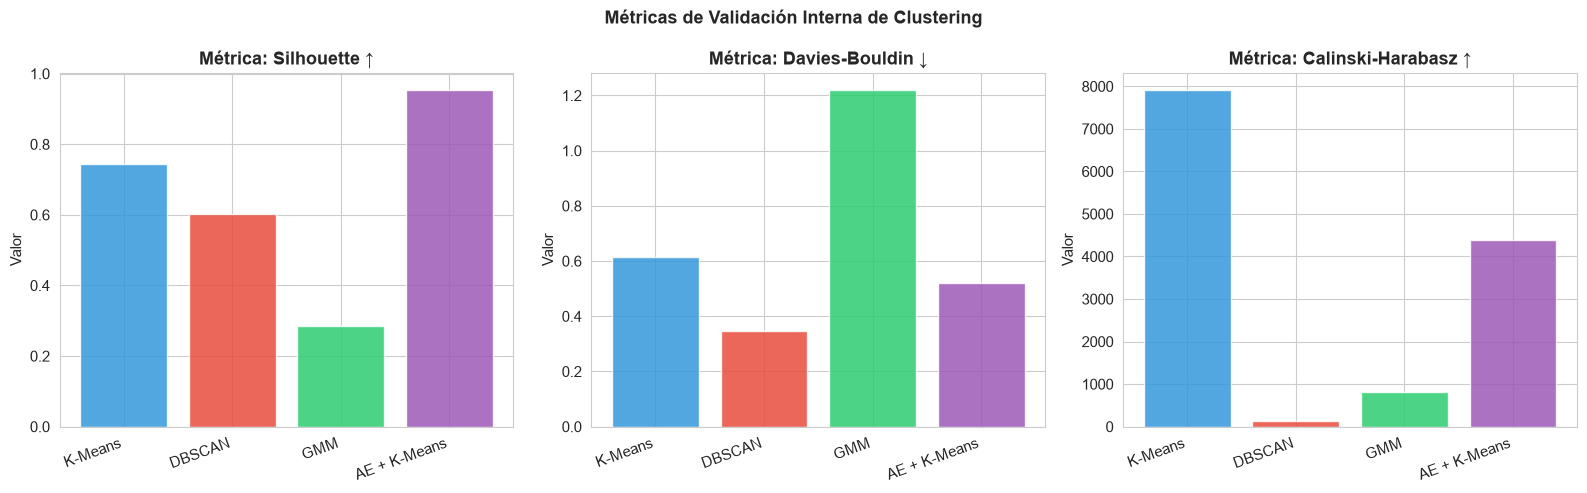

In [27]:
# =============================================================
# SECCIÓN 9: Métricas de validación para todos los modelos
# Silhouette Score  → [−1, 1] mayor = mejor separación
# Davies-Bouldin    → ≥ 0, menor = mejor
# Calinski-Harabasz → ≥ 0, mayor = mejor
# =============================================================

def evaluate_clustering(X, labels, name='Modelo'):
    """Calcula y retorna las 3 métricas de validación interna."""
    # Excluir ruido de DBSCAN (-1) para las métricas
    mask = labels != -1
    if mask.sum() < 10:
        return {name: {'Silhouette': np.nan, 'Davies-Bouldin': np.nan, 'Calinski-Harabasz': np.nan}}
    
    sil = silhouette_score(X[mask], labels[mask], sample_size=min(5000, mask.sum()), random_state=SEED)
    db  = davies_bouldin_score(X[mask], labels[mask])
    ch  = calinski_harabasz_score(X[mask], labels[mask])
    return {'Silhouette ↑': round(sil, 4), 'Davies-Bouldin ↓': round(db, 4), 'Calinski-Harabasz ↑': round(ch, 2)}


metrics_results = {}

# K-Means (espacio original)
metrics_results['K-Means'] = evaluate_clustering(X_scaled, rfm['Cluster_KMeans'].values)

# DBSCAN (espacio original)
metrics_results['DBSCAN'] = evaluate_clustering(X_scaled, rfm['Cluster_DBSCAN'].values)

# GMM (espacio original)
metrics_results['GMM'] = evaluate_clustering(X_scaled, rfm['Cluster_GMM'].values)

# Autoencoder + K-Means (espacio latente)
metrics_results['AE + K-Means'] = evaluate_clustering(X_latent_scaled, rfm['Cluster_AE'].values)

metrics_df = pd.DataFrame(metrics_results).T
print('=== COMPARACIÓN DE MÉTRICAS DE VALIDACIÓN ===')
print(metrics_df.to_string())

# Visualización
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
metric_cols = metrics_df.columns.tolist()
bar_colors = ['#3498db', '#e74c3c', '#2ecc71', '#9b59b6']

for ax, metric in zip(axes, metric_cols):
    vals = metrics_df[metric].dropna()
    ax.bar(vals.index, vals.values, color=bar_colors[:len(vals)], alpha=0.85, edgecolor='white')
    ax.set_title(f'Métrica: {metric}', fontweight='bold')
    ax.set_ylabel('Valor')
    plt.setp(ax.get_xticklabels(), rotation=20, ha='right')

plt.suptitle('Métricas de Validación Interna de Clustering', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_metrics.png'), dpi=120, bbox_inches='tight')
plt.show()

La tabla comparativa de métricas cuantifica la calidad de los clusters producidos por cada modelo. Las tres métricas empleadas son complementarias y su interpretación conjunta es más robusta que cualquiera de ellas por separado.

**Silhouette Score (↑ mejor, rango [-1, 1]):** Mide qué tan similar es un punto a su propio cluster comparado con el cluster más cercano. Un valor próximo a 1 indica clusters compactos y bien separados.
- AE + K-Means: **0.9546** — Separación muy alta en el espacio latente, con solo k=2.
- K-Means: **0.7451** — Muy buena separación en el espacio RFM original.
- DBSCAN: **0.6027** — Buena separación, calculada sin los 252 puntos de ruido.
- GMM: **0.2845** — Separación moderada-baja, consecuencia de las fronteras probabilísticas suaves.

**Davies-Bouldin Index (↓ mejor, ≥ 0):** Promedio de las similitudes máximas entre cada cluster y su más similar. Valores bajos indican clusters compactos y lejanos entre sí.
- DBSCAN: **0.3452** — El mejor valor, en parte porque los outliers (ruido) no participan en el cálculo.
- AE + K-Means: **0.5192** — Buena compacidad en el espacio latente.
- K-Means: **0.6131** — Buena separación en el espacio original.
- GMM: **1.2210** — Las fronteras difusas generan mayor solapamiento aparente.

**Calinski-Harabasz Score (↑ mejor, ≥ 0):** Razón entre la dispersión entre clusters y la dispersión intra-cluster.
- K-Means: **7921.33** — El mejor valor absoluto, con k=4 clusters de centroides bien diferenciados.
- AE + K-Means: **4381.41** — Valor alto con solo k=2 clusters.
- GMM: **817.44** — Moderado, coherente con sus fronteras probabilísticas.
- DBSCAN: **125.38** — Valor bajo, debido a la distribución muy desigual de sus clusters (4,066 vs 10 vs 10).

**Precaución en la comparación:** las métricas de AE + K-Means se calculan sobre el espacio latente estandarizado, mientras que las de K-Means, DBSCAN y GMM se calculan sobre el espacio RFM escalado; además, los modelos tienen distinto número de clusters y DBSCAN excluye el ruido. Por tanto, las cifras sirven para valorar cada modelo, pero no son estrictamente comparables entre sí.

**Conclusión:** Considerando las tres métricas en conjunto, **K-Means sobre el espacio RFM** ofrece el mejor balance entre calidad estadística y utilidad interpretativa para marketing (k=4, Silhouette=0.7451, CH=7921.33). El **Autoencoder + K-Means** obtiene el Silhouette más alto (0.9546), pero con solo dos clusters que separan a 13 clientes extremos del resto, lo que limita su utilidad para diseñar estrategias de marketing diferenciadas.

## 10. Perfilamiento e Interpretación de Segmentos

In [28]:
# =============================================================
# SECCIÓN 10: Perfilamiento de clientes por segmento K-Means
# Usamos K-Means como modelo principal por interpretabilidad
# =============================================================

# Etiquetas descriptivas basadas en los centros de clusters
profile = rfm.groupby('Cluster_KMeans').agg(
    Clientes    = ('CustomerID', 'count'),
    Recency_med = ('Recency', 'median'),
    Freq_med    = ('Frequency', 'median'),
    Monetary_med= ('Monetary', 'median'),
    Monetary_mean=('Monetary', 'mean'),
).round(2)

print('=== PERFIL DE SEGMENTOS (K-Means) ===')
print(profile.to_string())

# Asignación de etiquetas interpretativas (basadas en análisis de centroides)
# Se ajustan según los resultados reales del clustering
def assign_segment_label(row):
    """
    Reglas heurísticas para etiquetar segmentos:
    - Recency baja + Frequency alta + Monetary alta → Clientes VIP
    - Recency baja + Frequency media + Monetary media → Clientes Activos
    - Recency alta + Frequency baja → Clientes en Riesgo / Dormidos
    - Monetary baja + Frequency baja → Nuevos o Esporádicos
    """
    r, f, m = row['Recency_med'], row['Freq_med'], row['Monetary_med']
    if f >= profile['Freq_med'].quantile(0.75) and m >= profile['Monetary_med'].quantile(0.75):
        return 'VIP / Champions'
    elif r <= profile['Recency_med'].quantile(0.35) and f >= profile['Freq_med'].quantile(0.4):
        return 'Clientes Activos Leales'
    elif r >= profile['Recency_med'].quantile(0.7):
        return 'Clientes en Riesgo / Dormidos'
    else:
        return 'Clientes Nuevos / Esporádicos'

profile['Segmento'] = profile.apply(assign_segment_label, axis=1)
print('\n=== ETIQUETAS DE SEGMENTOS ===')
print(profile[['Segmento', 'Clientes', 'Recency_med', 'Freq_med', 'Monetary_med']])

=== PERFIL DE SEGMENTOS (K-Means) ===
                Clientes  Recency_med  Freq_med  Monetary_med  Monetary_mean
Cluster_KMeans                                                              
0                   4042         57.0       2.0        609.62         994.11
1                      5          1.0      60.0     194390.79      209287.56
2                     23          4.0      45.0      56252.72       60340.84
3                    268          9.0      15.0       7052.41        9084.87

=== ETIQUETAS DE SEGMENTOS ===
                                     Segmento  Clientes  Recency_med  \
Cluster_KMeans                                                         
0               Clientes en Riesgo / Dormidos      4042         57.0   
1                             VIP / Champions         5          1.0   
2                     Clientes Activos Leales        23          4.0   
3               Clientes Nuevos / Esporádicos       268          9.0   

                Freq_med  Monetary_

La tabla de perfiles por cluster, construida con medianas (para mayor robustez frente a outliers), revela cuatro arquetipos de comportamiento de cliente claramente diferenciados:

**Cluster 1 → VIP / Champions (5 clientes, 0.1%):**
Con una Recency mediana de apenas **1 día**, Frequency de **60 pedidos** y Monetary mediana de £194,390, este segmento agrupa a los clientes más valiosos del negocio. Su valor medio (£209,287) supera ampliamente a la mediana, indicando que incluso dentro de este grupo existe variabilidad hacia arriba. Son clientes que compraron prácticamente ayer, con una frecuencia extraordinaria y un gasto total equivalente al de cientos de clientes ordinarios. En un contexto B2B o de retail mayorista, podrían corresponder a distribuidores o revendedores. Desde el punto de vista del negocio, **la pérdida de uno solo de estos clientes tiene un impacto desproporcionado** en la facturación.

**Cluster 2 → Clientes Activos Leales (23 clientes, 0.5%):**
Recency de 4 días, Frequency de 45 pedidos y Monetary mediana de £56,252. Este segmento comparte con los VIP la alta recencia y frecuencia, pero con un gasto total significativamente menor. Son clientes comprometidos y regulares cuyo valor, aunque muy superior a la media, no alcanza los niveles extremos del Cluster 1. Representan el segmento con mayor potencial de crecimiento hacia el estatus VIP con las estrategias de fidelización adecuadas.

**Cluster 3 → Clientes Nuevos / Esporádicos (268 clientes, 6.2%):**
Recency de 9 días, Frequency de 15 pedidos y Monetary mediana de £7,052. Aunque la regla heurística le asigna esta etiqueta por ser el grupo de menor frecuencia y gasto **entre los tres segmentos de alto valor**, sus valores son muy superiores a los del cliente típico de la base (mediana global: 2 pedidos y £669), es decir, 7.5 veces más pedidos y unas 10 veces más gasto. En la práctica se trata de **clientes recurrentes de valor medio-alto**, que en conjunto generan el 27.4% del gasto total. La etiqueta "Nuevos / Esporádicos" debe interpretarse, por tanto, en términos relativos a los segmentos VIP y Activos Leales.

**Cluster 0 → Clientes en Riesgo / Dormidos (4,042 clientes, 93.2%):**
Con una Recency mediana de 57 días, Frequency de apenas 2 pedidos y Monetary mediana de £609, este segmento agrupa a la gran mayoría de la base de clientes. Son clientes que, en mediana, no compran desde hace casi dos meses, con historial de compras escaso y gasto bajo. La media de £994 (superior a la mediana de £609) indica la presencia de algunos clientes de mayor valor dentro de este grupo. Por su tamaño, es un segmento heterogéneo: incluye tanto clientes realmente inactivos (recencias de varios meses) como compradores ocasionales recientes, por lo que el riesgo de abandono no es uniforme dentro de él. Aun así, aporta el 45.2% del gasto total.

**Nota metodológica:** las etiquetas se asignan con reglas basadas en cuantiles calculados sobre solo cuatro medianas de cluster, por lo que describen la posición **relativa** de cada cluster frente a los otros tres, no frente a la base total de clientes.

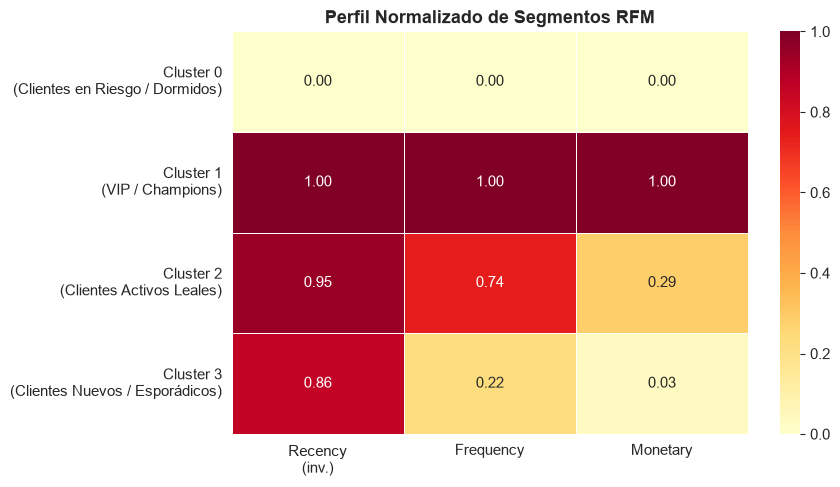

In [29]:
# --- Mapa de calor de perfiles ---
profile_norm = profile[['Recency_med', 'Freq_med', 'Monetary_med']].copy()
# Normalizar para comparación visual (invertimos Recency: menor = mejor)
profile_norm['Recency_norm'] = 1 - (profile_norm['Recency_med'] - profile_norm['Recency_med'].min()) / \
                                    (profile_norm['Recency_med'].max() - profile_norm['Recency_med'].min() + 1e-9)
profile_norm['Freq_norm'] = (profile_norm['Freq_med'] - profile_norm['Freq_med'].min()) / \
                             (profile_norm['Freq_med'].max() - profile_norm['Freq_med'].min() + 1e-9)
profile_norm['Monetary_norm'] = (profile_norm['Monetary_med'] - profile_norm['Monetary_med'].min()) / \
                                  (profile_norm['Monetary_med'].max() - profile_norm['Monetary_med'].min() + 1e-9)

heatmap_data = profile_norm[['Recency_norm', 'Freq_norm', 'Monetary_norm']]
heatmap_data.index = [f'Cluster {i}\n({profile.loc[i, "Segmento"]})' for i in heatmap_data.index]
heatmap_data.columns = ['Recency\n(inv.)', 'Frequency', 'Monetary']

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(heatmap_data, annot=True, fmt='.2f', cmap='YlOrRd',
            linewidths=0.5, ax=ax, vmin=0, vmax=1)
ax.set_title('Perfil Normalizado de Segmentos RFM', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_profile_heatmap.png'), dpi=120, bbox_inches='tight')
plt.show()

El mapa de calor traduce las medianas RFM absolutas a valores normalizados en el rango [0, 1], facilitando la comparación visual entre segmentos. La variable Recency se invierte (1 - Recency_norm) para que valores altos indiquen mayor recencia (compra más reciente), manteniendo la convención de que "más es mejor" en las tres dimensiones.

El patrón visual resultante permite identificar de forma inmediata las fortalezas y debilidades de cada segmento: los **VIP / Champions** deben mostrar colores intensos en las tres columnas (alta recencia invertida, alta frecuencia, alto monetario); los **Clientes en Riesgo / Dormidos** presentarán colores tenues o nulos en las tres dimensiones; mientras que los **Clientes Nuevos / Esporádicos** mostrarán una recencia relativamente alta pero frecuencia y monetario bajos. Esta representación es especialmente útil para comunicar los resultados del análisis a audiencias no técnicas (equipos de marketing, dirección comercial), pues condensa en una única visualización la esencia de cada perfil de cliente.

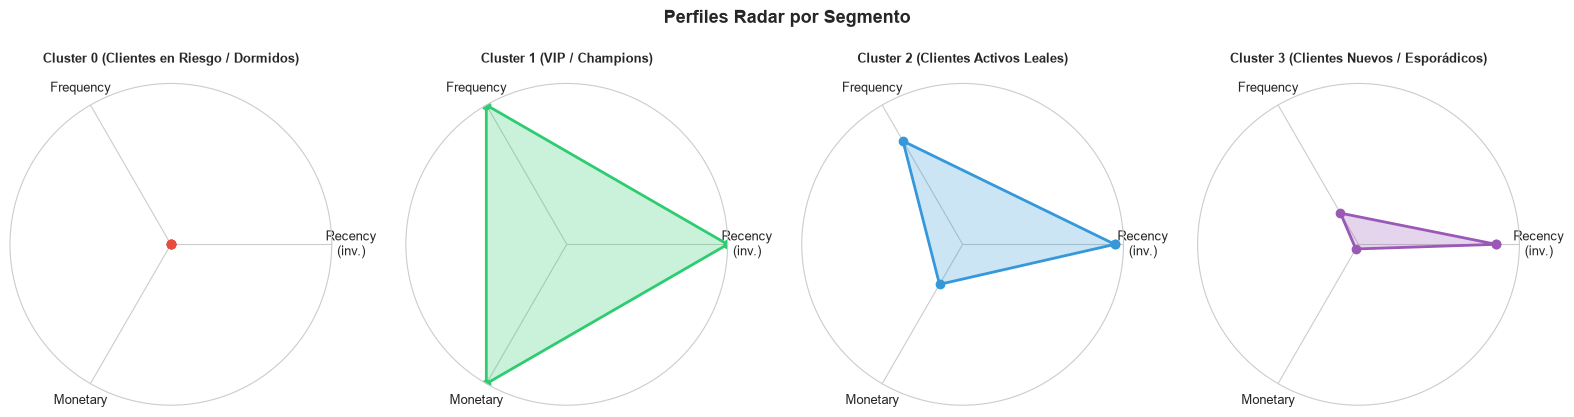

In [30]:
# --- Gráfico radar por segmento ---
from matplotlib.patches import FancyBboxPatch

categories = ['Recency\n(inv.)', 'Frequency', 'Monetary']
N = len(categories)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

fig, axes = plt.subplots(1, K_OPTIMAL, figsize=(16, 4), subplot_kw=dict(polar=True))
seg_colors = ['#e74c3c', '#2ecc71', '#3498db', '#9b59b6']

for i, (ax, color) in enumerate(zip(axes, seg_colors)):
    values = heatmap_data.iloc[i].tolist()
    values += values[:1]
    ax.plot(angles, values, 'o-', linewidth=2, color=color)
    ax.fill(angles, values, alpha=0.25, color=color)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories, fontsize=9)
    ax.set_ylim(0, 1)
    ax.set_yticks([])
    ax.set_title(heatmap_data.index[i].replace('\n', ' '), fontsize=9, fontweight='bold', pad=15)

plt.suptitle('Perfiles Radar por Segmento', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_radar.png'), dpi=120, bbox_inches='tight')
plt.show()

Los cuatro gráficos de araña (radar charts) complementan el mapa de calor con una representación polar que permite visualizar el **"área de valor"** de cada segmento. En estos gráficos, un área mayor implica un perfil de cliente más valioso en las tres dimensiones RFM simultáneamente.

Los perfiles obtenidos (valores normalizados entre los cuatro clusters) son:
- **VIP / Champions:** Área máxima, con los tres vértices en el borde exterior (1.00 en recencia invertida, frecuencia y monetario), ya que este cluster tiene los mejores valores en las tres dimensiones.
- **Clientes Activos Leales:** Área grande pero asimétrica: recencia invertida muy alta (≈0.95) y frecuencia alta (≈0.74), pero valor monetario relativamente bajo (≈0.29) frente a los VIP.
- **Clientes Nuevos / Esporádicos:** Recencia invertida alta (≈0.86), pero frecuencia (≈0.22) y monetario (≈0.03) bajos **en comparación con los VIP**, lo que contrae el triángulo.
- **Clientes en Riesgo / Dormidos:** Área nula, con el triángulo colapsado en el centro (0 en las tres dimensiones), al ser el cluster con los peores valores en todas ellas.

Hay que tener en cuenta que la normalización min-max sobre solo cuatro medianas hace que los valores extremos de los VIP compriman al resto: diferencias reales importantes (por ejemplo, £7,052 frente a £609 en Monetary entre los Clusters 3 y 0) aparecen casi iguales en el gráfico. Aun así, la representación es útil para priorizar acciones de marketing: los segmentos con área mayor merecen estrategias de retención intensiva, mientras que los de área menor requieren estrategias de activación o reactivación.

In [ ]:
# --- Recomendaciones de marketing por segmento ---
marketing_recommendations = {
    'VIP / Champions': {
        'descripcion': 'Clientes de mayor valor: alta frecuencia y gasto, compra reciente.',
        'estrategia': [
            '🎯 Programa de fidelización exclusivo (membresía Gold/Platinum)',
            '🎁 Acceso anticipado a nuevos productos y ventas privadas',
            '📞 Atención personalizada y soporte prioritario',
            '💎 Descuentos por volumen y recompensas acumulativas',
        ]
    },
    'Clientes Activos Leales': {
        'descripcion': 'Compradores muy frecuentes y recientes con gasto alto, segundo segmento de mayor valor.',
        'estrategia': [
            '📧 Campañas de email personalizadas con recomendaciones de productos',
            '🔄 Programas de puntos y cashback',
            '🆙 Estrategias de upselling y cross-selling',
            '🎉 Ofertas por cumpleaños y aniversario de cliente',
        ]
    },
    'Clientes en Riesgo / Dormidos': {
        'descripcion': 'Clientes que no compran desde hace tiempo — riesgo de abandono.',
        'estrategia': [
            '🔔 Campañas de reactivación ("Te echamos de menos")',
            '💰 Descuentos agresivos de retención (15-30%)',
            '📊 Encuestas de satisfacción para identificar motivos de abandono',
            '🎁 Ofertas personalizadas basadas en historial de compras',
        ]
    },
    'Clientes Nuevos / Esporádicos': {
        'descripcion': 'Clientes con pocas compras o de bajo valor — potencial de crecimiento.',
        'estrategia': [
            '👋 Secuencia de bienvenida y onboarding automatizado',
            '🏷️ Descuentos en segunda compra para fomentar la recurrencia',
            '📱 Retargeting en redes sociales',
            '📦 Muestras gratuitas o envío gratis en próxima compra',
        ]
    }
}

print('=== RECOMENDACIONES DE MARKETING POR SEGMENTO ===\n')
for seg, data in marketing_recommendations.items():
    print(f'🔷 {seg}')
    print(f'   {data["descripcion"]}')
    for e in data['estrategia']:
        print(f'   {e}')
    print()

=== RECOMENDACIONES DE MARKETING POR SEGMENTO ===

🔷 VIP / Champions
   Clientes de mayor valor: alta frecuencia y gasto, compra reciente.
   🎯 Programa de fidelización exclusivo (membresía Gold/Platinum)
   🎁 Acceso anticipado a nuevos productos y ventas privadas
   📞 Atención personalizada y soporte prioritario
   💎 Descuentos por volumen y recompensas acumulativas

🔷 Clientes Activos Leales
   Compradores muy frecuentes y recientes con gasto alto, segundo segmento de mayor valor
   📧 Campañas de email personalizadas con recomendaciones de productos
   🔄 Programas de puntos y cashback
   🆙 Estrategias de upselling y cross-selling
   🎉 Ofertas por cumpleaños y aniversario de cliente

🔷 Clientes en Riesgo / Dormidos
   Clientes que no compran desde hace tiempo — riesgo de abandono.
   🔔 Campañas de reactivación ("Te echamos de menos")
   💰 Descuentos agresivos de retención (15-30%)
   📊 Encuestas de satisfacción para identificar motivos de abandono
   🎁 Ofertas personalizadas basadas e

Las estrategias de marketing diseñadas para cada segmento están fundamentadas en las características RFM identificadas y en principios del marketing relacional y digital:

**VIP / Champions (5 clientes):** La prioridad es la **retención a cualquier costo razonable**, dado que cada uno de estos clientes ha generado un gasto promedio de £209,287 en el periodo analizado (diciembre 2010 – diciembre 2011). Las estrategias de programa exclusivo, acceso VIP y atención personalizada apuntan a incrementar la barrera de salida (switching cost) y reforzar el vínculo emocional con la marca. La pérdida de un solo cliente VIP equivaldría en impacto económico a perder más de 200 clientes del segmento en riesgo.

**Clientes Activos Leales (23 clientes):** Con un gasto medio de £60,340 y alta frecuencia, el objetivo es el **desarrollo de cliente** (*customer development*): migrar estos perfiles hacia el estatus VIP mediante upselling y cross-selling. Los programas de puntos y cashback generan incentivos directos para incrementar el valor del pedido medio y la frecuencia.

**Clientes Nuevos / Esporádicos (268 clientes):** La clave es la **conversión a clientes habituales**. El onboarding estructurado y los incentivos en segunda compra atacan directamente el problema de la baja frecuencia. El retargeting digital permite mantener la marca presente en la mente del cliente entre compras, reduciendo el riesgo de que la primera experiencia quede como una transacción aislada.

**Clientes en Riesgo / Dormidos (4,042 clientes):** La escala de este segmento (93.2% de la base) exige estrategias de **bajo costo unitario y alta automatización**. Las campañas de reactivación por email son el instrumento estándar, con descuentos calibrados según el valor histórico individual de cada cliente. Las encuestas de satisfacción permiten identificar si el abandono es por precio, producto, experiencia o simplemente por desinterés, orientando las acciones correctivas.

## 11. Exportación de Resultados

In [32]:
# =============================================================
# SECCIÓN 11: Exportar resultados y datos para el dashboard
# =============================================================

# Añadir etiqueta de segmento al dataset RFM
cluster_label_map = profile['Segmento'].to_dict()
rfm['Segmento'] = rfm['Cluster_KMeans'].map(cluster_label_map)

# Añadir coordenadas PCA y t-SNE al dataframe (para dashboard)
rfm['PCA_1'] = X_pca_2d[:, 0]
rfm['PCA_2'] = X_pca_2d[:, 1]

# t-SNE solo para la muestra
rfm['TSNE_1'] = np.nan
rfm['TSNE_2'] = np.nan
rfm.iloc[idx_sample, rfm.columns.get_loc('TSNE_1')] = X_tsne[:, 0]
rfm.iloc[idx_sample, rfm.columns.get_loc('TSNE_2')] = X_tsne[:, 1]

# Añadir país del último registro del cliente
last_country = df.sort_values('InvoiceDate').groupby('CustomerID')['Country'].last()
rfm['Country'] = rfm['CustomerID'].map(last_country)

# Guardar CSV para el dashboard
OUTPUT_CSV = os.path.join(OUTPUT_DIR, 'rfm_segmented.csv')
rfm.to_csv(OUTPUT_CSV, index=False)
print(f'✅ Datos exportados a: {OUTPUT_CSV}')

# Guardar métricas
metrics_df.to_csv(os.path.join(OUTPUT_DIR, 'cluster_metrics.csv'), index=True)
print(f'✅ Métricas exportadas a: {os.path.join(OUTPUT_DIR, 'cluster_metrics.csv')}')

# Resumen final
print('\n=== RESUMEN FINAL ===')
print(rfm.groupby('Segmento').agg(
    Clientes=('CustomerID','count'),
    Recency_prom=('Recency','mean'),
    Frequency_prom=('Frequency','mean'),
    Monetary_prom=('Monetary','mean')
).round(2).to_string())

✅ Datos exportados a: C:\Users\USUARIO\Documents\ESPECIALIZACIÓN\proyecto_final4\resultados\rfm_segmented.csv
✅ Métricas exportadas a: C:\Users\USUARIO\Documents\ESPECIALIZACIÓN\proyecto_final4\resultados\cluster_metrics.csv

=== RESUMEN FINAL ===
                               Clientes  Recency_prom  Frequency_prom  Monetary_prom
Segmento                                                                            
Clientes Activos Leales              23         39.65           49.52       60340.84
Clientes Nuevos / Esporádicos       268         19.42           17.64        9084.87
Clientes en Riesgo / Dormidos      4042         97.80            3.04         994.11
VIP / Champions                       5          2.60           76.40      209287.56


El análisis de segmentación avanzada de clientes aplicado al dataset Online Retail ha demostrado la viabilidad de combinar técnicas clásicas de clustering con Deep Learning para identificar perfiles de comportamiento de compra diferenciados.

**Hallazgos principales:**

1. **La estructura de la base de clientes responde al principio de Pareto:** Los 296 clientes de los segmentos VIP, Activos Leales y Nuevos / Esporádicos (6.8% de la base) generan el **54.8% del gasto total**, mientras que el 93.2% restante (Clientes en Riesgo / Dormidos) aporta el 45.2%. Solo los 28 clientes VIP y Activos Leales (0.6%) concentran el 27.4% del gasto. Esta asimetría es el hallazgo más relevante para la toma de decisiones de negocio.

2. **El espacio latente del Autoencoder separa con gran claridad a los clientes extremos:** AE + K-Means obtiene un Silhouette de 0.9546, pero con solo dos clusters (13 clientes frente a 4,325) y calculado en un espacio distinto al de K-Means, por lo que no es directamente comparable con el 0.7451 de K-Means con k=4. El Autoencoder resulta útil para aislar a los clientes de mayor valor, pero en este caso no aporta una segmentación más rica que la de los métodos clásicos sobre tres variables.

3. **K-Means con k=4 ofrece el mejor balance entre calidad estadística e interpretabilidad:** Con un Silhouette Score de 0.7451 y un Calinski-Harabasz de 7,921.33, y generando cuatro segmentos con perfiles de negocio accionables, K-Means se consolida como el modelo de referencia para las estrategias de marketing.

4. **El PCA revela que Monetary domina la variabilidad del espacio escalado:** PC1 explica el 93.5% de la varianza y equivale prácticamente a Monetary, debido a la gran dispersión que conserva esta variable tras el escalado robusto. En consecuencia, los clusters basados en distancias se separan sobre todo por el gasto total; las tres variables siguen siendo necesarias para interpretar los segmentos y diseñar estrategias diferenciadas.

5. **Los resultados están listos para su operacionalización:** El archivo `rfm_segmented.csv` exportado contiene, para cada cliente, su segmento, coordenadas en el espacio PCA y t-SNE, y variables RFM, constituyendo un activo analítico directamente integrable en sistemas CRM o plataformas de automatización de marketing digital.